In [ ]:
import os
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from scipy.signal import butter, filtfilt, iirnotch, lfilter_zi, lfilter, find_peaks

Filter & Preprocessing Utilities

In [ ]:
def notch_filter(data, f0=60.0, fs=500, Q=30):
    b, a = iirnotch(f0, Q, fs)
    return filtfilt(b, a, data)

In [ ]:
def butter_bandpass(lowcut, highcut, fs, order=4):
    nyquist = 0.5 * fs
    low = lowcut / nyquist
    high = highcut / nyquist
    return butter(order, [low, high], btype='band')

In [ ]:
def bandpass_filter(data, lowcut, highcut, fs, order=4):
    b, a = butter_bandpass(lowcut, highcut, fs, order)
    return filtfilt(b, a, data)

In [ ]:
def moving_window_rms(signal, window_size):
    return np.sqrt(np.convolve(signal ** 2, np.ones(window_size) / window_size, mode='same'))

Per Gesture Processing

In [ ]:
def process_gesture_data(path, gesture_name, fs=500, num_channels=8, window_size=200, plot=False):
    df = pd.read_csv(path)
    smoothed_signals = []
    filtered_signals = []
    all_rectified_data = []
    for i in range(num_channels):
        raw = df.iloc[:, i].values
        band = bandpass_filter(raw, 8, 248, fs)
        notch = notch_filter(band, 60, fs)
        # notch = preprocess_filters(raw)
        filtered_signals.append(notch)
        all_rectified_data.append(abs(notch))
        rms = moving_window_rms(abs(notch), window_size)
        smoothed_signals.append(rms)

    filt_df = pd.DataFrame(smoothed_signals).T
    filt_df.columns = [f"Channel {i+1}" for i in range(num_channels)]
    filt_df['stimulus_state'] = df['stimulus_state'].values
    filt_df['gesture'] = gesture_name

    if plot:
        fig, axes = plt.subplots(num_channels, 1, figsize=(10, 12), sharex=True)
        fig.suptitle(f"Filtered EMG Data - {gesture_name}", fontsize=16)
        for i in range(num_channels):
            axes[i].plot(filt_df.iloc[:,i], linewidth=0.6)
            axes[i].set_title(f'Channel {i + 1}')
            axes[i].grid(True)
        axes[-1].set_xlabel("Time Points")
        plt.tight_layout(rect=[0, 0, 1, 0.96])
        plt.show()

    return filt_df, pd.DataFrame(filtered_signals).T, pd.DataFrame(all_rectified_data).T

In [ ]:
def rest_baseline(df):
    rest_rows = df[df['stimulus_state'] == 'rest'].iloc[:, :8]
    return rest_rows.mean().values, rest_rows.std().values

In [ ]:
def adjust_labels(df, gesture):
    mean, std = rest_baseline(df)
    high = (df.iloc[:, :8] > mean + std).all(axis=1)
    low = (df.iloc[:, :8] < mean + std).all(axis=1)
    df.loc[high, 'stimulus_state'] = 'hold'
    df.loc[low, 'stimulus_state'] = 'rest'
    df.loc[df['stimulus_state'].isin(['up', 'down']), 'stimulus_state'] = 'hold'
    df.loc[df['stimulus_state'] == 'hold', 'stimulus_state'] = gesture
    return df.iloc[:, :8].assign(stimulus_state=df['stimulus_state'])

Feature Extraction

In [ ]:
def max_labels(seq):
    return Counter(seq).most_common(1)[0][0]

In [ ]:
def sliding_window(df, window_size=200, stride=100):
    signal = df.iloc[:, :-1].to_numpy()
    labels = df.iloc[:, -1].to_numpy()
    X, y = [], []

    for i in range(0, len(signal) - window_size + 1, stride):
        win = signal[i:i+window_size]
        label = max_labels(labels[i:i+window_size])
        X.append(win)
        y.append(label)

    return np.array(X), np.array(y)

In [ ]:
def slide_filt(df, window_size=200, stride=100):
    signal = df.iloc[:, :].to_numpy()
    X= []

    for i in range(0, len(signal) - window_size + 1, stride):
        win = signal[i:i+window_size]
        X.append(win)

    return np.array(X)

In [ ]:
def compute_rms(windows):
    return np.sqrt(np.mean(np.square(windows), axis=1))

In [ ]:
def mean_absolute_value(data):
    return np.mean(np.abs(data), axis=1)
def count_zero_crossings_diff(data):
    diff_signal = np.diff(np.sign(data), axis=1)
    return np.sum(np.abs(diff_signal), axis = 1) / 2
def slope_sign_changes(data, threshold=0.01):
    sign_changes = np.diff(np.sign(np.diff(data, axis=1)), axis=1) != 0
    magnitude_check = np.abs(np.diff(data, n=2, axis=1)) > threshold
    return np.sum(sign_changes & magnitude_check, axis=1)
def waveform_length(data):
    return np.sum(np.abs(np.diff(data, axis = 1)), axis = 1)

Main General Pipeline

In [ ]:
def process_all_gestures(gesture_file_map, fs=500, plot_each=False):
    all_data = []
    filt_only_all =  []
    recti_all = []
    for gesture, path in gesture_file_map.items():
        print(f"Processing: {gesture} from {os.path.basename(path)}")
        df, fitlered_sig, recti_sig = process_gesture_data(path, gesture, fs=fs, plot=plot_each)
        df = adjust_labels(df, gesture)
        all_data.append(df)
        filt_only_all.append(fitlered_sig)
        recti_all.append(recti_sig)

    combined = pd.concat(all_data, ignore_index=True)
    combined_filtered = pd.concat(filt_only_all, ignore_index=True)

    win_data, win_labels = sliding_window(combined, window_size=200, stride=20)
    fitlered_win = slide_filt(combined_filtered, window_size=200, stride=20)
    recti_win = slide_filt(combined_filtered, window_size=200, stride=20)

    X_rms = compute_rms(win_data)
    X_mav = mean_absolute_value(win_data)
    X_zc = count_zero_crossings_diff(fitlered_win)
    X_ssc = slope_sign_changes(recti_win)
    X_wl = waveform_length(win_data)

    return X_rms, X_mav, X_zc, X_ssc, X_wl, win_labels, combined

File Input

In [ ]:
gesture_files = {
    "wflex" : "E:/RTMC_NML_Public/data_2025_09_24_DEF_P6_Full_Window_0_full_window_log.csv",
    "wexten" :"E:/RTMC_NML_Public/Mindrove_venv/Data/P0_DJ/Offline_Data/15thSept2025/Smart_select_wexten_data_2025_09_15_0_unfilt.csv",
    # "wradial" : "E:/Mindrove_venv/Data_Gestures_RTMC/Smart_select_WRadial_data_2025_06_02_Dheemant_Actual_0_unfilt.csv",
    # "wulnar" : "E:/Mindrove_venv/Data_Gestures_RTMC/Smart_select_WUlnar_data_2025_06_02_Dheemant_Actual_0_unfilt.csv",
    # "FThumb" : "E:/Mindrove_venv\Data_Gestures_RTMC/Smart_select_FThumb_data_2025_06_02_Dheemant_Actual_0_unfilt.csv",
    "FIndex" : "E:/RTMC_NML_Public/Mindrove_venv/Data/P0_DJ/Offline_Data/15thSept2025/Smart_select_findex_data_2025_09_15_0_unfilt.csv",
    # "FMiddle" : "E:\Mindrove_venv\Smart_select_FMiddle_data_2025_06_02_Dheemant_Actual_0_unfilt.csv",
    # "FRing" : "E:\Mindrove_venv\Smart_select_FRing_data_2025_06_02_Dheemant_Actual_0_unfilt.csv",
    # "FPinky" : "E:\Mindrove_venv\Smart_select_FPinky_data_2025_06_02_Dheemant_Actual_0_unfilt.csv",
    # "FThumb_Iso" : "E:\Mindrove_venv\Smart_select_FThumb_Iso_data_2025_06_03_Dheemant_Iso_0_unfilt.csv",
    # "FIndex_Iso" : "E:\Mindrove_venv\Smart_select_FIndex_Iso_data_2025_06_03_Dheemant_Iso_0_unfilt.csv",
    # "FMiddle_Iso" : "E:\Mindrove_venv\Smart_select_FMiddle_Iso_data_2025_06_03_Dheemant_Iso_0_unfilt.csv",
    # "FRing_Iso" : "E:\Mindrove_venv\Smart_select_FRing_Iso_data_2025_06_03_Dheemant_Iso_0_unfilt.csv",

}

Processing: wflex from Smart_select_wflex_data_2025_09_15_0_unfilt.csv


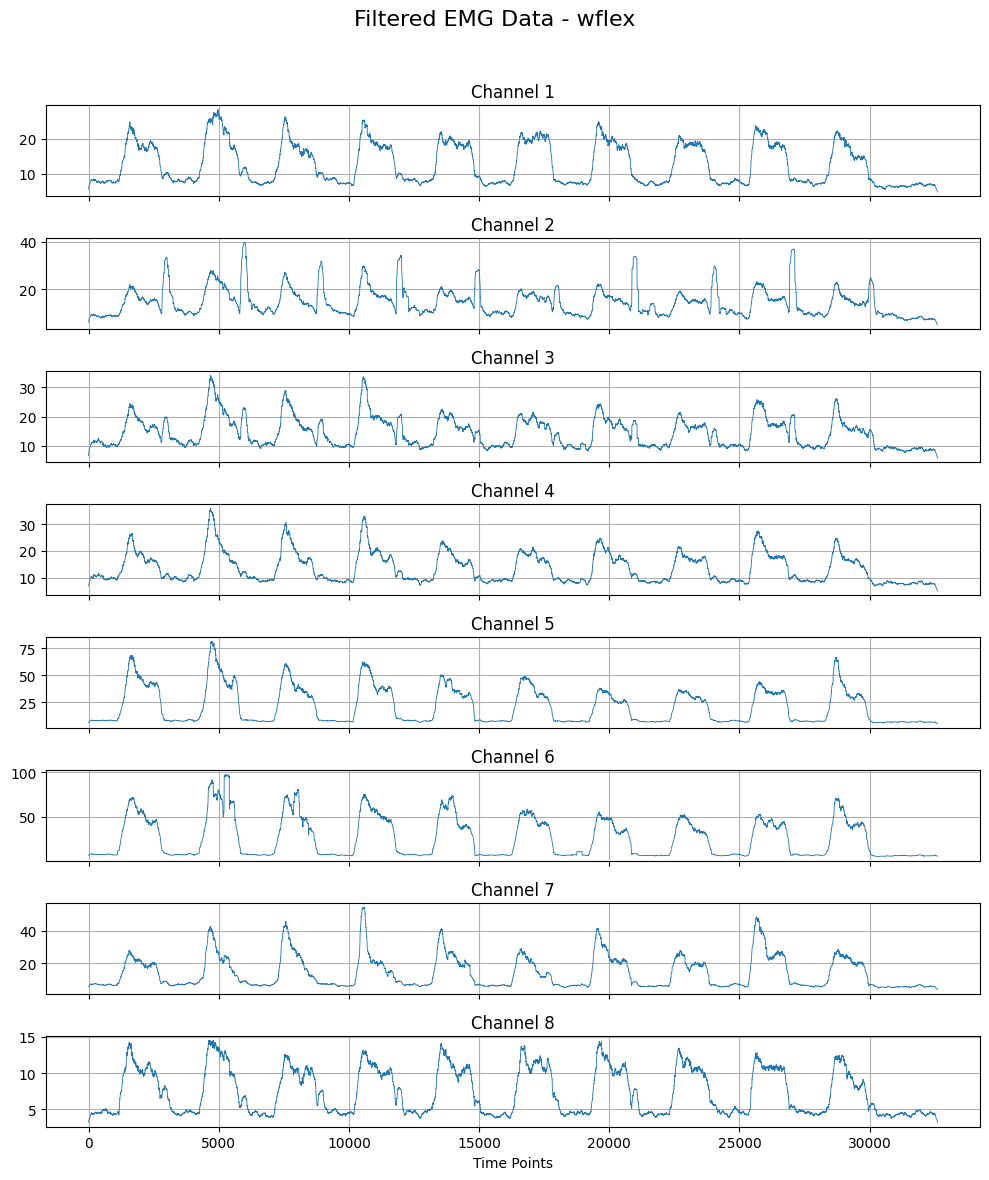

Processing: wexten from Smart_select_wexten_data_2025_09_15_0_unfilt.csv


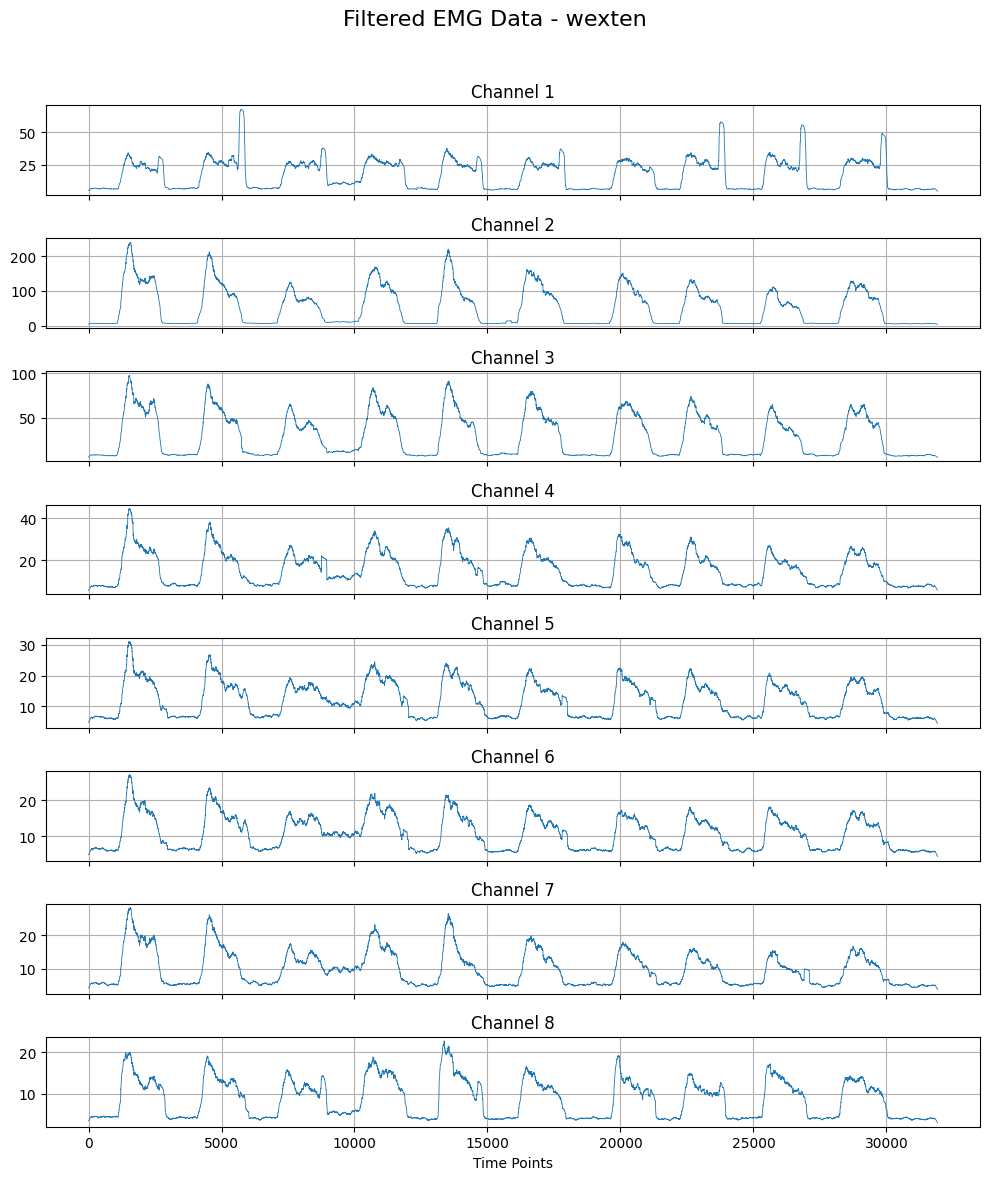

Processing: FIndex from Smart_select_findex_data_2025_09_15_0_unfilt.csv


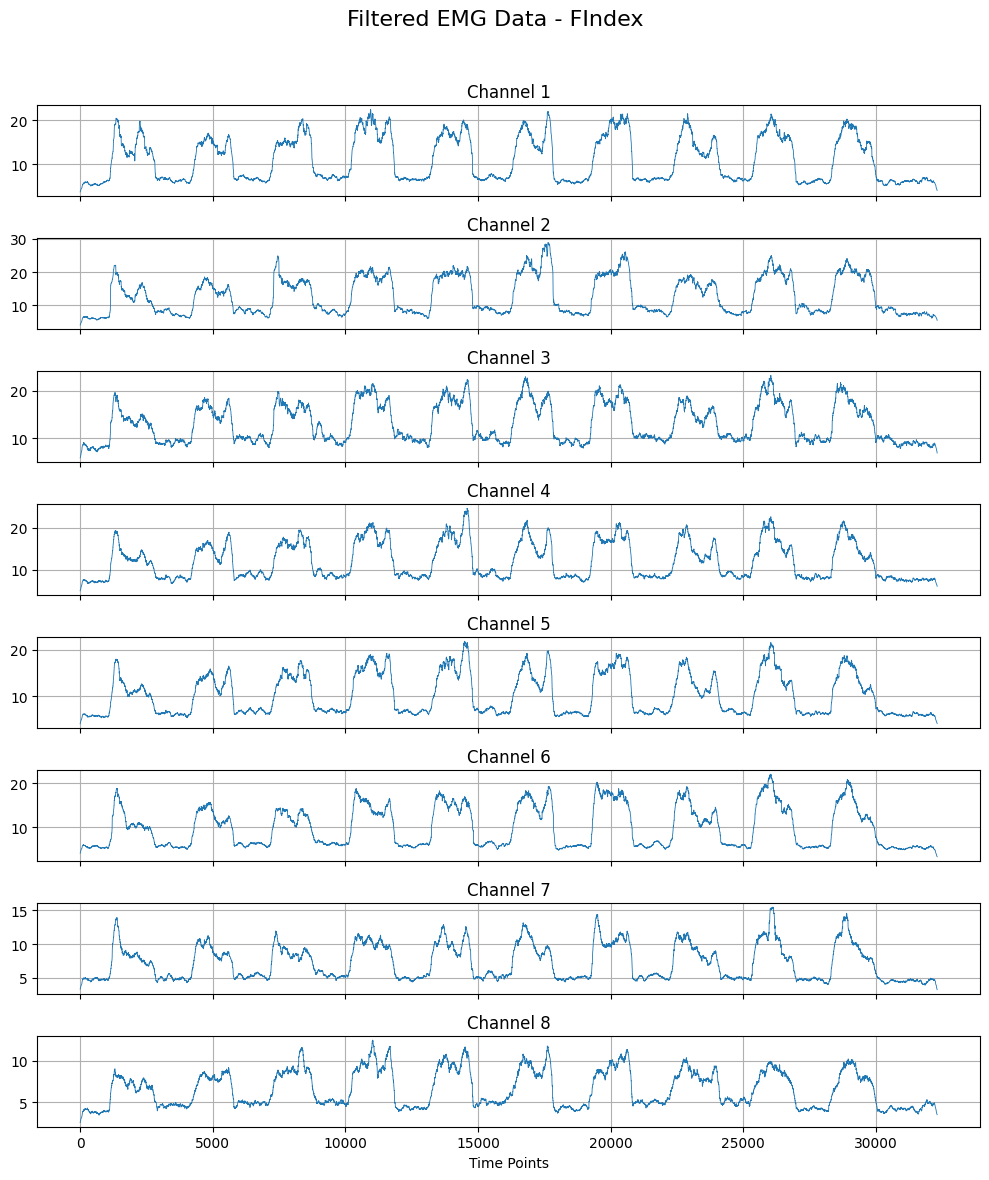

In [ ]:
X_rms, X_mav, X_zc, X_ssc, X_wl, win_labels, combined = process_all_gestures(gesture_files, plot_each=True)

In [ ]:
combined

,Channel 1,Channel 2,Channel 3,Channel 4,Channel 5,Channel 6,Channel 7,Channel 8,stimulus_state
0,5.479215,6.059130,6.566894,6.888434,6.104780,7.187294,5.671096,3.223763,rest
1,5.519935,6.117336,6.629739,6.939825,6.116696,7.187678,5.722874,3.228038,rest
2,5.535281,6.142720,6.840017,7.001790,6.156615,7.214433,5.737904,3.238173,rest
3,5.596231,6.171649,6.981448,7.007493,6.159780,7.236710,5.767128,3.270543,rest
4,5.627305,6.176570,7.126582,7.036391,6.164859,7.279176,5.774873,3.316767,rest
...,...,...,...,...,...,...,...,...,...
96841,4.071709,5.489544,6.974074,6.136407,4.257056,3.410939,3.308986,3.548452,rest
96842,3.996121,5.489409,6.937357,6.068641,4.187839,3.365939,3.300482,3.545712,rest
96843,3.988833,5.480807,6.906981,6.061818,4.186941,3.365424,3.296934,3.545349,rest
96844,3.983291,5.476014,6.885732,6.016233,4.155933,3.347606,3.278026,3.542727,rest


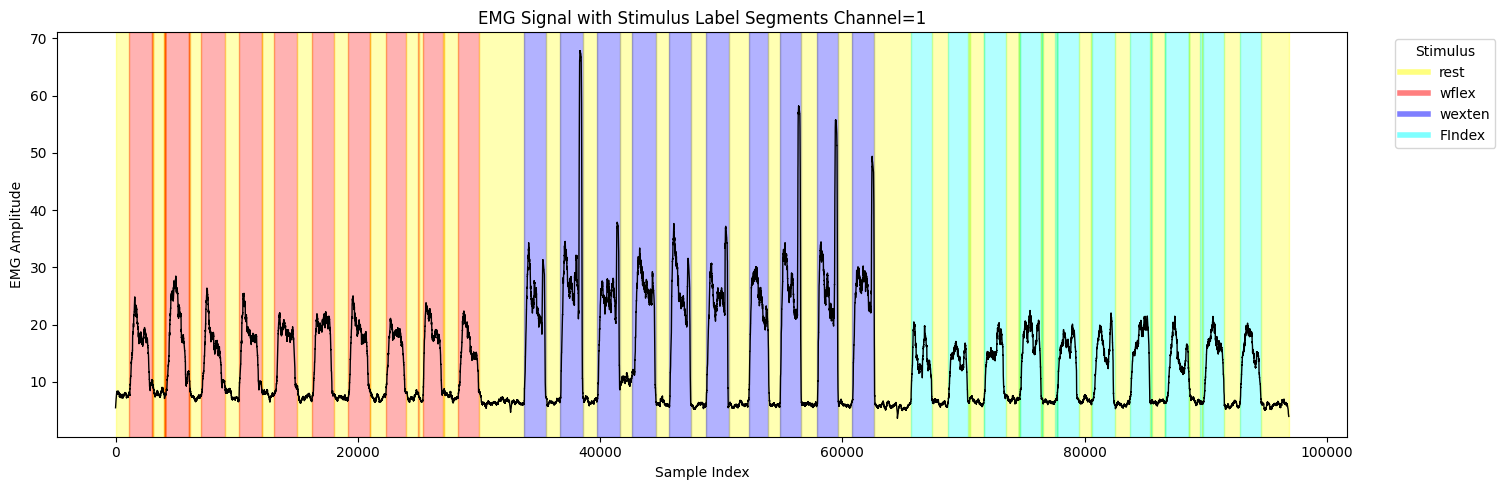

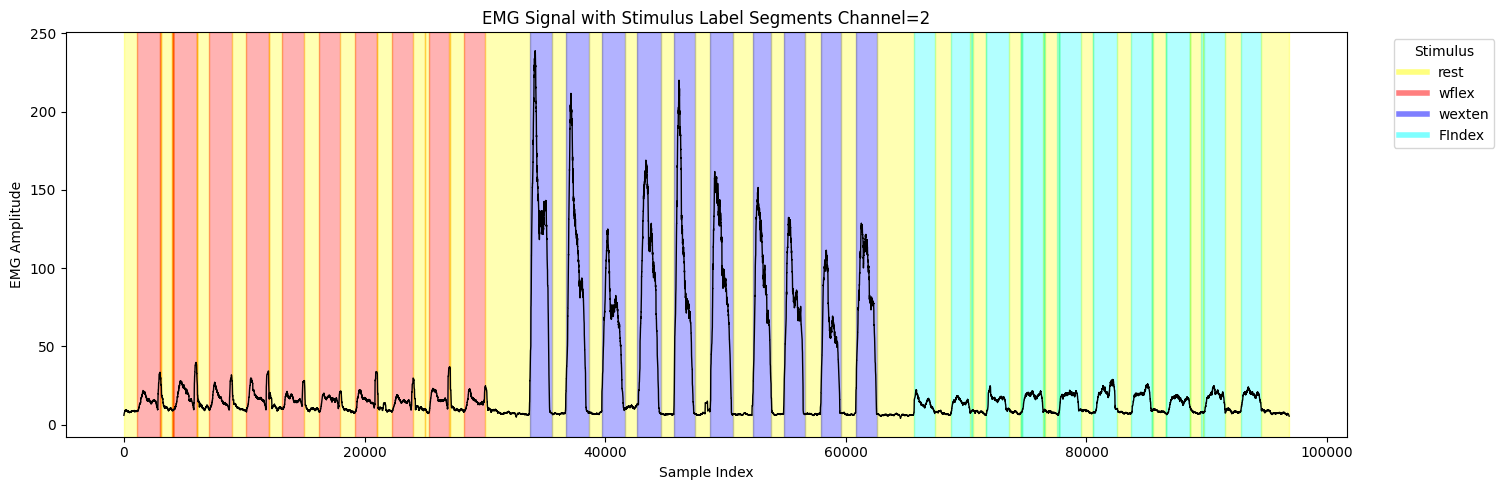

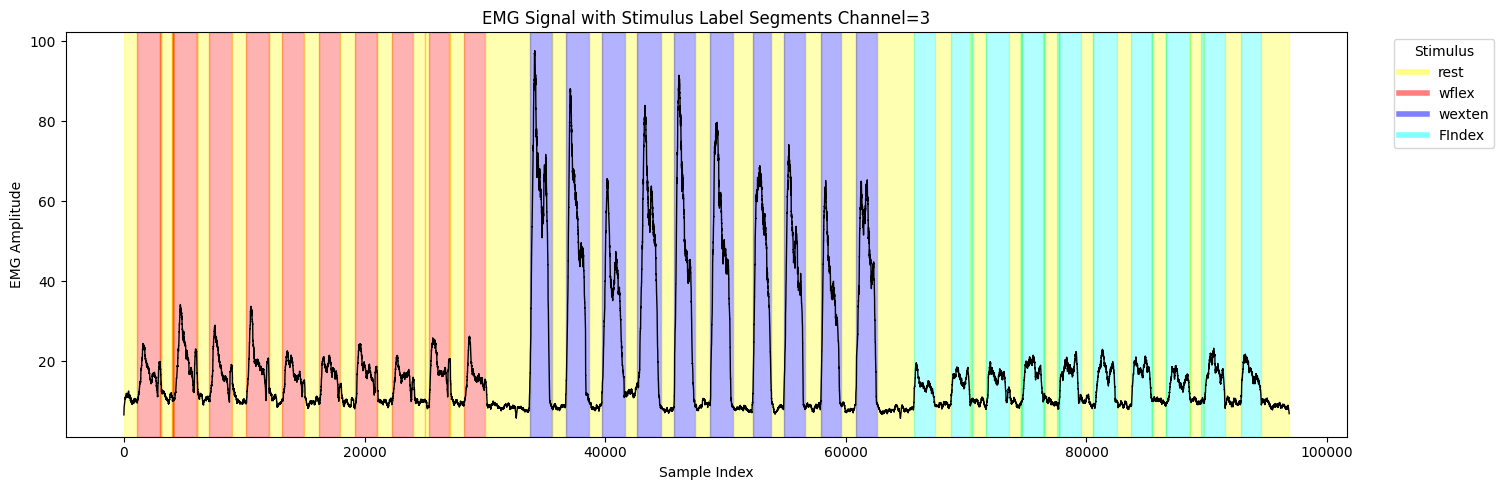

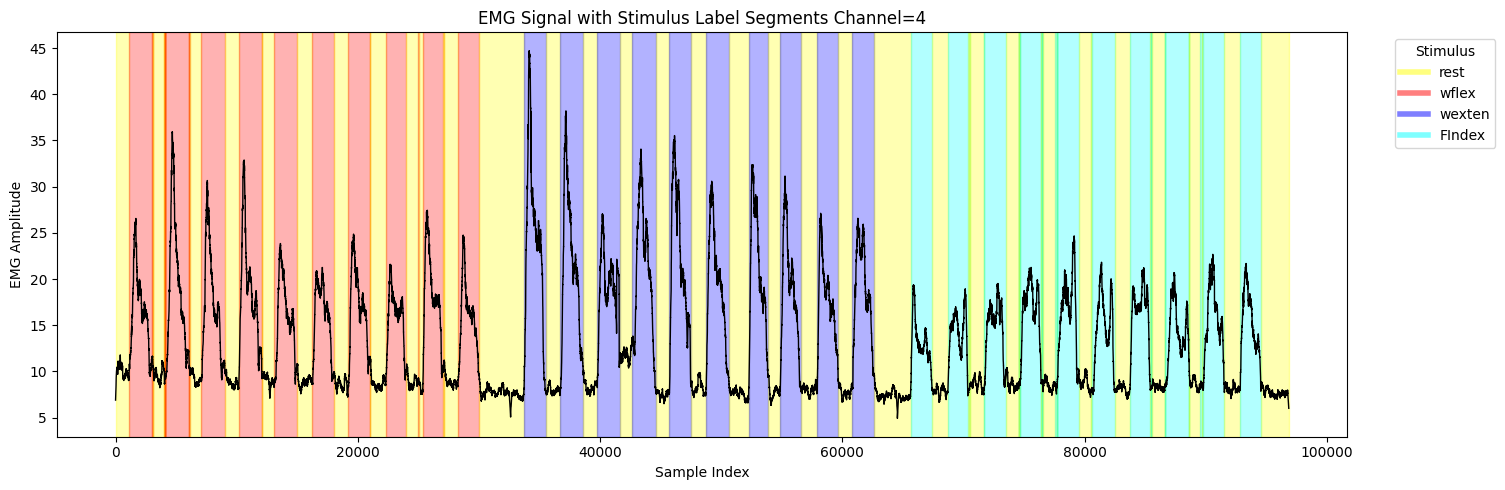

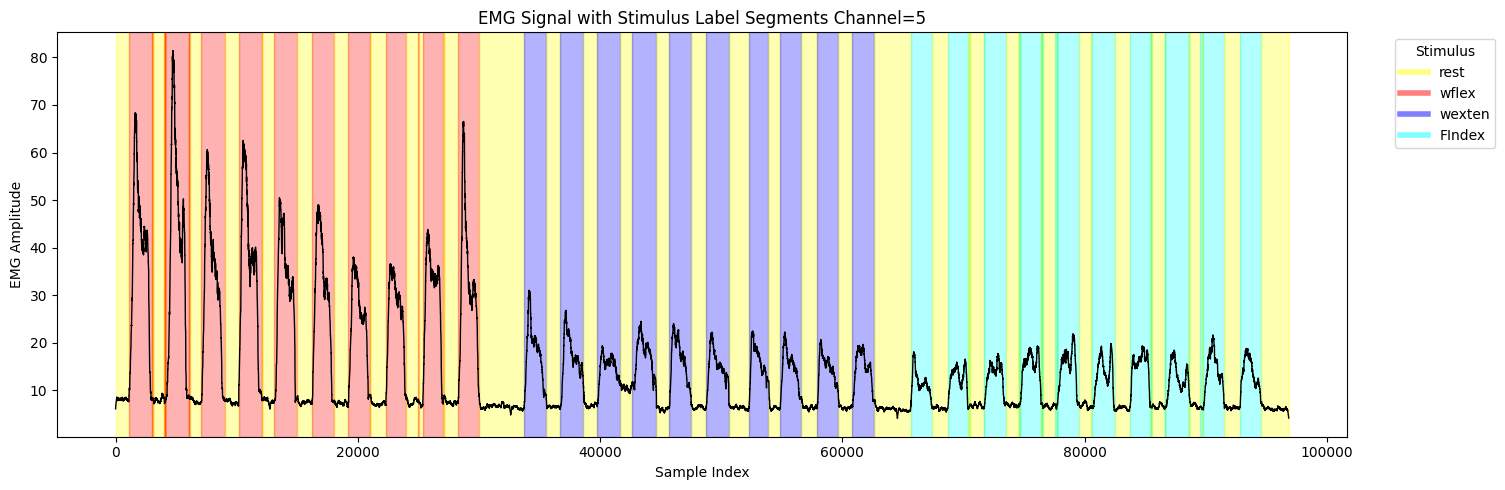

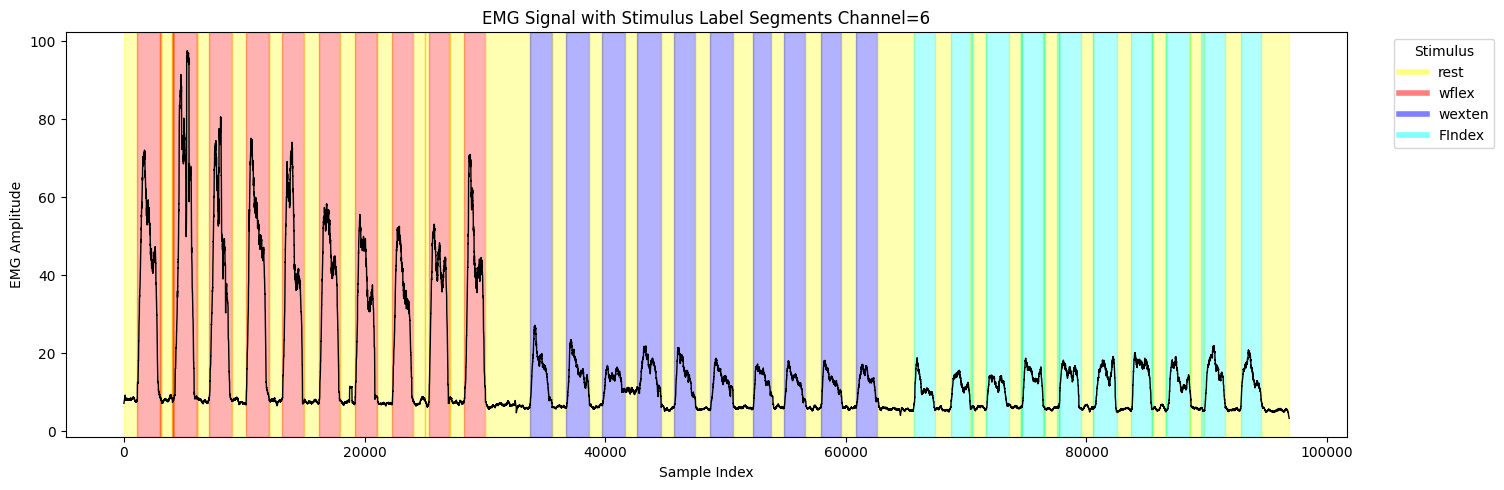

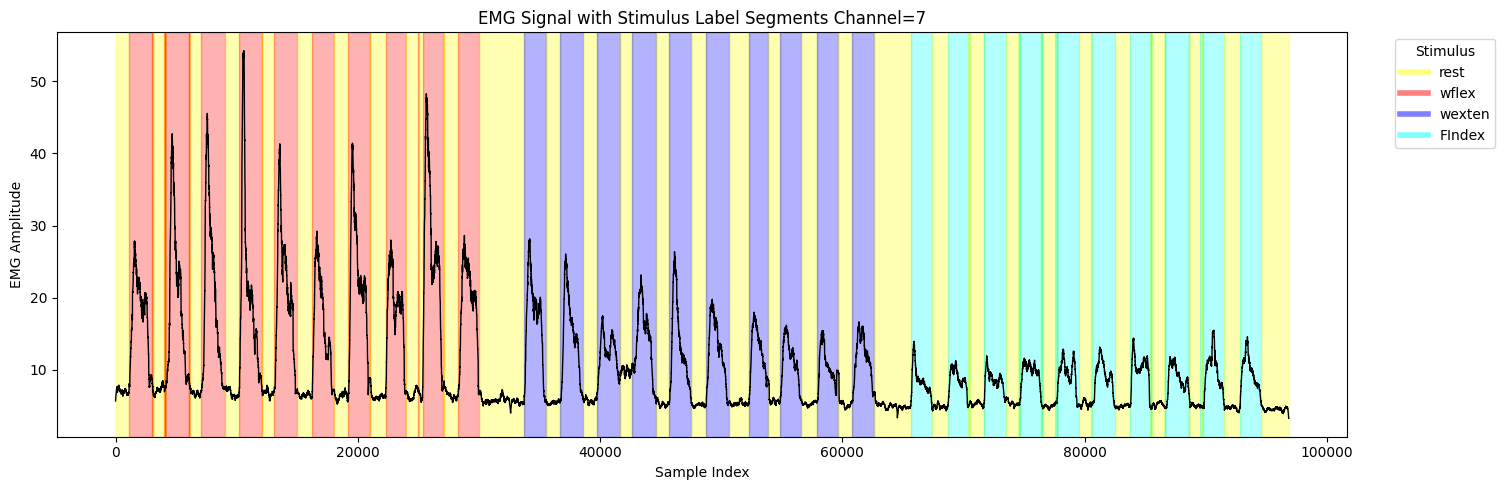

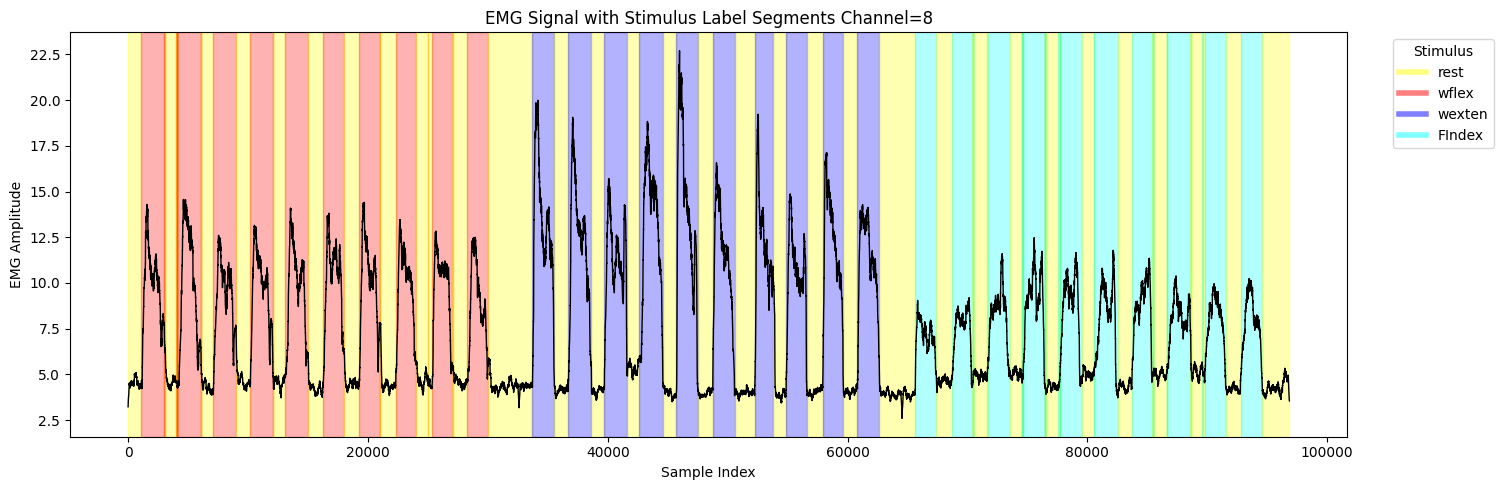

In [ ]:
label_colors = {
    'rest': 'yellow',
    'wflex': 'red',
    'wexten': 'blue',

    'FIndex': 'cyan'
}
for chan in range(8):
    emg_channel = combined.iloc[:, chan].to_numpy()
    labels = combined['stimulus_state'].to_numpy()

    time = np.arange(len(emg_channel))

    plt.figure(figsize=(15, 5))
    plt.plot(time, emg_channel, label='Channel 1', color='black', linewidth=1)

    # Segment shading based on labels
    prev_label = labels[0]
    start_idx = 0

    for i in range(1, len(labels)):
        if labels[i] != prev_label:
            color = label_colors.get(prev_label, 'gray')  # fallback to gray if label not found
            plt.axvspan(start_idx, i, color=color, alpha=0.3, label=prev_label)
            start_idx = i
            prev_label = labels[i]

    # Final segment
    color = label_colors.get(prev_label, 'gray')
    plt.axvspan(start_idx, len(labels), color=color, alpha=0.3, label=prev_label)

    plt.title(f"EMG Signal with Stimulus Label Segments Channel={chan+1}")
    plt.xlabel("Sample Index")
    plt.ylabel("EMG Amplitude")

    # Only show unique labels in legend
    handles = [
        plt.Line2D([0], [0], color=label_colors[label], lw=4, alpha=0.5)
        for label in label_colors
    ]
    plt.legend(handles, label_colors.keys(), title='Stimulus', bbox_to_anchor=(1.12, 1))

    plt.tight_layout()
    plt.show()


In [ ]:
print(f"Shape of RMS features: {X_rms.shape}")
print(f"Shape of MAV features: {X_mav.shape}")
print(f"Shape of ZC features: {X_zc.shape}")
print(f"Shape of SSC features: {X_ssc.shape}")
print(f"Shape of WL features: {X_wl.shape}")



Shape of RMS features: (4833, 8)
Shape of MAV features: (4833, 8)
Shape of ZC features: (4833, 8)
Shape of SSC features: (4833, 8)
Shape of WL features: (4833, 8)


In [ ]:
X_features = np.concatenate([X_rms, X_mav, X_zc,X_ssc,X_wl], axis=1)

In [ ]:
print(f"combined feature matrix: {X_features.shape}")

combined feature matrix: (4833, 40)


In [ ]:
X_features_df = pd.DataFrame(X_features)

Train-Test Split

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X_features_df, win_labels, test_size=0.2, random_state=42)
unique_classes = np.unique(y_train)

Normalize

In [ ]:
from sklearn.preprocessing import StandardScaler

In [ ]:
scaler = StandardScaler()
scaler.fit(X_train)

StandardScaler()

In [ ]:
# Transform the training data
X_train_df_scaled = scaler.transform(X_train)
X_train_df_scaled = pd.DataFrame(X_train_df_scaled)
X_train_df_scaled

,0,1,2,3,4,5,6,7,8,9,...,30,31,32,33,34,35,36,37,38,39
0,-0.293200,-0.326411,-0.425285,-0.505190,0.334910,0.205819,-0.126422,0.016190,-0.301108,-0.348408,...,0.150995,-0.127638,-0.021176,0.112038,-0.000006,-0.129362,1.220718,1.181418,-0.026832,0.867998
1,0.944176,0.873772,1.063699,0.452983,-0.045452,-0.232476,-0.156409,1.029843,0.977996,0.884955,...,0.309363,-0.968268,0.587271,0.805243,0.810080,0.698818,-0.063802,-0.258551,-0.301648,0.909477
2,-0.411076,0.064061,-0.048871,-0.325373,-0.292378,-0.283714,-0.246670,-0.461063,-0.406620,0.012069,...,1.101204,0.012467,-0.224385,0.446695,0.148439,-0.123509,0.903388,0.395585,-0.138822,-0.193870
3,-0.879279,-0.554532,-0.678848,-0.926499,-0.718871,-0.609634,-0.669217,-0.961632,-0.881068,-0.548929,...,0.467731,0.993202,-0.880719,-0.618979,-0.722536,-0.949368,-0.772075,-0.692197,-0.731188,-1.194227
4,0.553314,-0.042673,-0.103890,0.627064,0.194634,0.118187,-0.278243,0.578800,0.544820,-0.037437,...,-0.007374,-0.688058,0.538010,-0.243696,-0.222915,0.528995,0.241434,-0.111259,-0.339288,0.976730
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3861,-0.367366,-0.433184,-0.516799,-0.382356,-0.384409,-0.372974,-0.561709,-0.215302,-0.391360,-0.430488,...,-1.115951,-0.407848,0.051160,-0.381045,-0.364988,0.026467,-0.221644,-0.191086,-0.430377,0.337588
3862,-0.635534,-0.444708,-0.571139,-0.775578,-0.587844,-0.488068,-0.443752,-0.770112,-0.632260,-0.438306,...,-0.640847,-0.267743,-0.721986,-0.528005,-0.590628,-0.976856,-0.669448,-0.544975,-0.552334,-0.950928
3863,1.649183,1.756731,1.904594,0.757879,-0.012201,-0.175985,0.208442,0.917451,1.698090,1.765275,...,1.259573,0.152572,1.332882,1.643966,2.252410,1.167825,0.057073,-0.163825,0.201677,1.276596
3864,0.764208,-0.191306,0.078710,1.109753,0.310131,-0.123597,-0.044270,1.066467,0.793081,-0.183492,...,-0.324110,-1.248478,0.839971,-0.254898,0.004978,0.869241,0.174534,-0.127090,-0.056621,0.872283


In [ ]:
# Transform the test data
X_test_df_scaled = scaler.transform(X_test)
X_test_df_scaled = pd.DataFrame(X_test_df_scaled)
X_test_df_scaled

,0,1,2,3,4,5,6,7,8,9,...,30,31,32,33,34,35,36,37,38,39
0,-0.895404,-0.503395,-0.550326,-0.855428,-0.734281,-0.676957,-0.801621,-0.824181,-0.897582,-0.497555,...,1.259573,1.133307,-0.795512,-0.557256,-0.612488,-0.916257,-0.762615,-0.649489,-0.784519,-0.807124
1,-0.921495,-0.571044,-0.725081,-1.050082,-0.767110,-0.646996,-0.727606,-0.916405,-0.923870,-0.566176,...,0.626099,-0.267743,-0.906365,-0.529734,-0.633139,-0.938423,-0.791139,-0.654507,-0.727293,-1.047558
2,-0.541178,0.043285,-0.140789,-0.400175,-0.460426,-0.314877,-0.271954,-0.210874,-0.540847,0.019633,...,-0.007374,-0.547953,-0.377606,0.162956,-0.168381,-0.262664,-0.135976,0.528614,0.200520,-0.067526
3,-0.981769,-0.579915,-0.711042,-0.962159,-0.745224,-0.662771,-0.781641,-1.072601,-0.985813,-0.574433,...,1.417941,0.432782,-0.903318,-0.620520,-0.674264,-0.835438,-0.762938,-0.694152,-0.783208,-1.137697
4,1.846217,1.722628,1.788358,1.219006,0.162212,-0.061077,0.499741,1.563572,1.893549,1.744461,...,1.259573,0.292677,1.323798,1.413710,1.459521,1.076554,0.002771,-0.176460,0.197228,1.358055
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
962,-0.844963,-0.545218,-0.668645,-0.847506,-0.667978,-0.601495,-0.673641,-0.986825,-0.846479,-0.539958,...,0.942836,0.012467,-0.838950,-0.590670,-0.702115,-0.917947,-0.715242,-0.623296,-0.655871,-1.080494
963,-0.924947,-0.561229,-0.653056,-0.886946,-0.718943,-0.640248,-0.748351,-1.093142,-0.927485,-0.555568,...,1.893046,1.973937,-0.871057,-0.621177,-0.721682,-0.991679,-0.745219,-0.660660,-0.772920,-1.103566
964,-0.881418,-0.491312,-0.580894,-0.841336,-0.658250,-0.599193,-0.759514,-0.942708,-0.885196,-0.485319,...,-1.115951,-1.108373,-0.624071,-0.470181,-0.618428,-0.900861,-0.687965,-0.546498,-0.736170,-0.746689
965,-0.722571,-0.484920,-0.582521,-0.768096,-0.604328,-0.511198,-0.463979,-0.853563,-0.721829,-0.479092,...,0.784468,0.432782,-0.703862,-0.508965,-0.560791,-0.647856,-0.649877,-0.553871,-0.498009,-1.037796


PCA

In [ ]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import LabelEncoder

In [ ]:
pca = PCA(n_components=0.95)  # Retain 95% variance
X_pca = pca.fit_transform(np.array(X_train_df_scaled))
X_pca_test = pca.transform(np.array(X_test_df_scaled))

In [ ]:
X_pca.shape, X_pca_test.shape

((3866, 16), (967, 16))

In [ ]:
# Extract eigenvalues (λ = variance explained by each PC)
lambdas = pca.explained_variance_

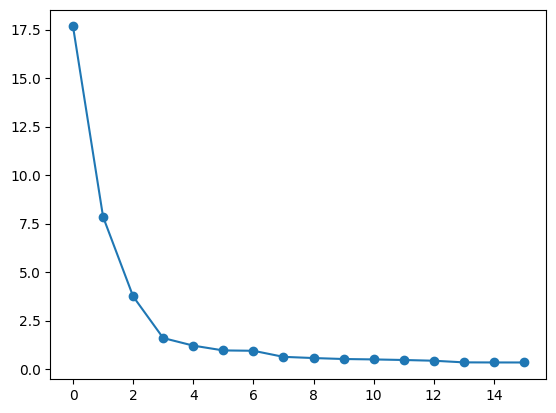

In [ ]:
plt.plot(range(X_pca.shape[1]),lambdas, "o-")

In [ ]:
# Convert string labels to integers
le = LabelEncoder()
numeric_labels = le.fit_transform(y_train)

In [ ]:
explained_variance = pca.explained_variance_ratio_ * 100
sum(explained_variance)

np.float64(95.36834371454171)

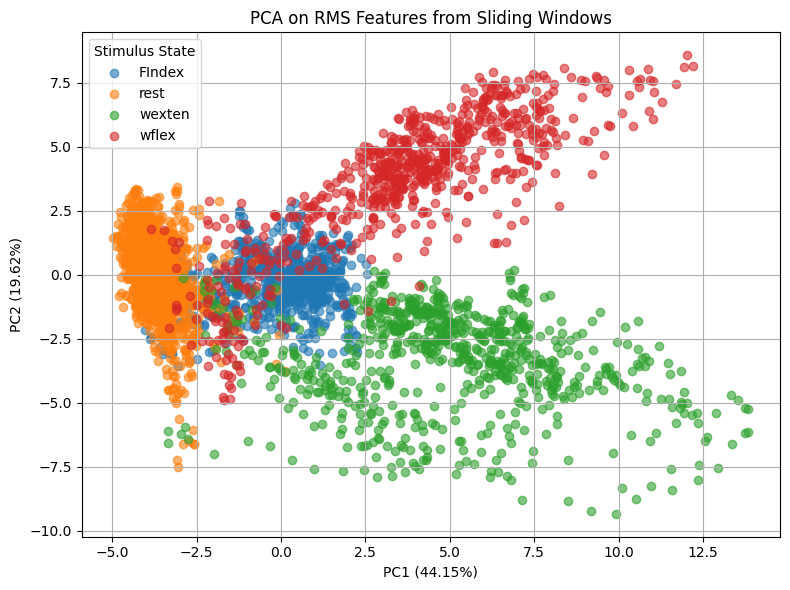

In [ ]:
# 4. Visualization
plt.figure(figsize=(8, 6))
for cls in np.unique(y_train):
    idx = y_train == cls
    plt.scatter(X_pca[idx, 0], X_pca[idx, 1], label=str(cls), alpha=0.6)

plt.title("PCA on RMS Features from Sliding Windows")
explained_variance = pca.explained_variance_ratio_ * 100
plt.xlabel(f"PC1 ({explained_variance[0]:.2f}%)", fontsize=10)
plt.ylabel(f"PC2 ({explained_variance[1]:.2f}%)", fontsize=10)
plt.legend(title="Stimulus State")
plt.grid(True)
plt.tight_layout()
plt.show()

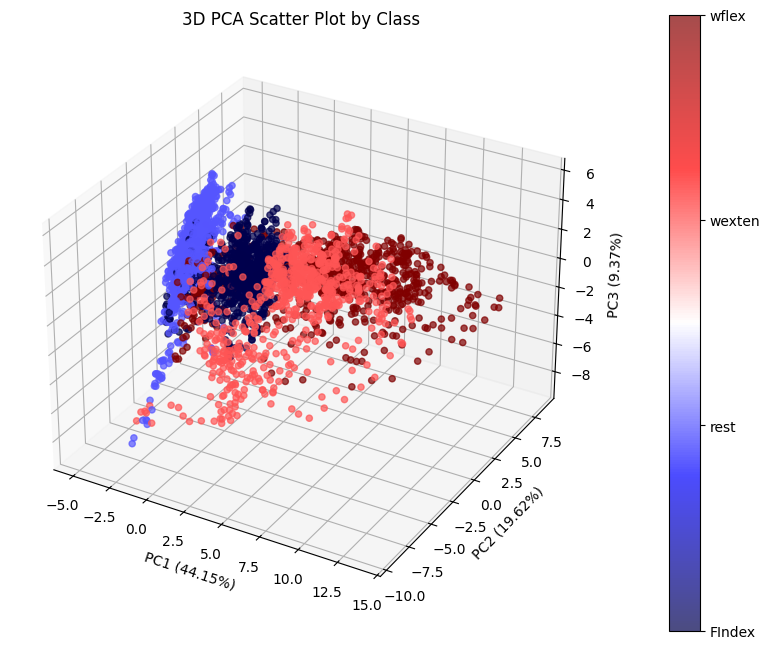

In [ ]:
# Plot 3D PCA
fig = plt.figure(figsize=(10, 8))
axis = fig.add_subplot(111, projection='3d')

scatter = axis.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2],
                       c=numeric_labels, cmap='seismic', alpha=0.7)

# Add colorbar with correct class names
cbar = plt.colorbar(scatter, pad=0.1)
cbar.set_ticks(np.unique(numeric_labels))
cbar.set_ticklabels(le.classes_)

explained_variance = pca.explained_variance_ratio_ * 100
axis.set_xlabel(f"PC1 ({explained_variance[0]:.2f}%)", fontsize=10)
axis.set_ylabel(f"PC2 ({explained_variance[1]:.2f}%)", fontsize=10)
axis.set_zlabel(f"PC3 ({explained_variance[2]:.2f}%)", fontsize=10)
plt.title("3D PCA Scatter Plot by Class")

plt.show()


t-SNE Visualization

In [ ]:
def plot_tsne_comparison(X_features, y_labels):
    from sklearn.manifold import TSNE
    # Apply t-SNE
    tsne = TSNE(n_components=2, random_state=42, perplexity=30)
    X_tsne = tsne.fit_transform(X_features)


    unique_labels = np.unique(y_labels)
    colors = plt.cm.seismic(np.linspace(0, 1, len(unique_labels)))
    label_colors = dict(zip(unique_labels, colors))


    for label in unique_labels:
        mask = y_labels == label
        plt.scatter(X_tsne[mask, 0], X_tsne[mask, 1],
                   color=label_colors[label], alpha=0.7, s=30, label=label)

    plt.xlabel('t-SNE Component 1', fontsize=12)
    plt.ylabel('t-SNE Component 2', fontsize=12)
    plt.title('t-SNE Visualization', fontsize=14, fontweight='bold')
    plt.legend()
    plt.grid(False)

    plt.tight_layout()
    plt.show()
# Modified function to rep

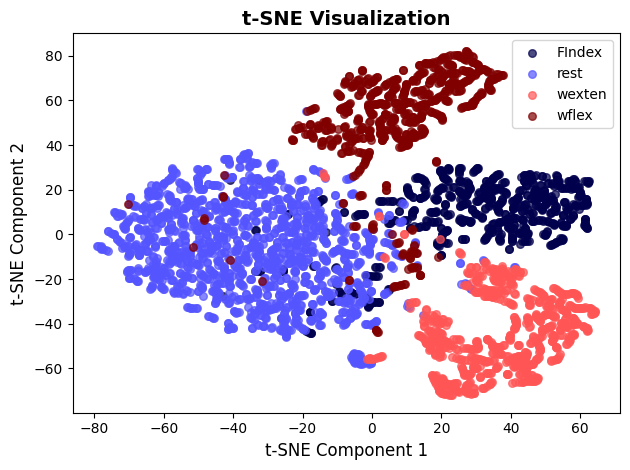

In [ ]:
plot_tsne_comparison(X_pca, y_train)

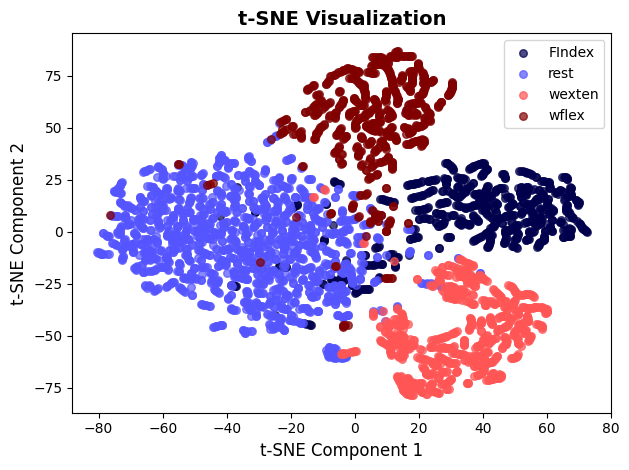

In [ ]:
plot_tsne_comparison(X_train_df_scaled, y_train)

VISUALIZATION

In [ ]:
label_colors = {
    'rest': 'yellow',
    'wflex': 'red',
    'wexten': 'blue',
    # 'wradial': 'green',
    # 'wulnar': 'orange',
    # 'FThumb': 'magenta',
    'FIndex': 'cyan',
    # 'FMiddle': 'purple',
    # 'FRing': 'brown',
    # 'FPinky': 'pink'
    # "FThumb_Iso" : "green",
    # "FIndex_Iso" : "red",
    # "FMiddle_Iso" : "blue",
    # "FRing_Iso" : "purple"

}

LDA APPLICATION

In [ ]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [ ]:
lda = LinearDiscriminantAnalysis()
lda.fit(X_pca, y_train)

LinearDiscriminantAnalysis()

In [ ]:
X_train_lda = lda.transform(X_pca)
X_test_lda = lda.transform(X_pca_test)

In [ ]:
colors = [label_colors[label] for label in unique_classes]

Plotting 2D scatter plot using the first two Linear Discriminants.


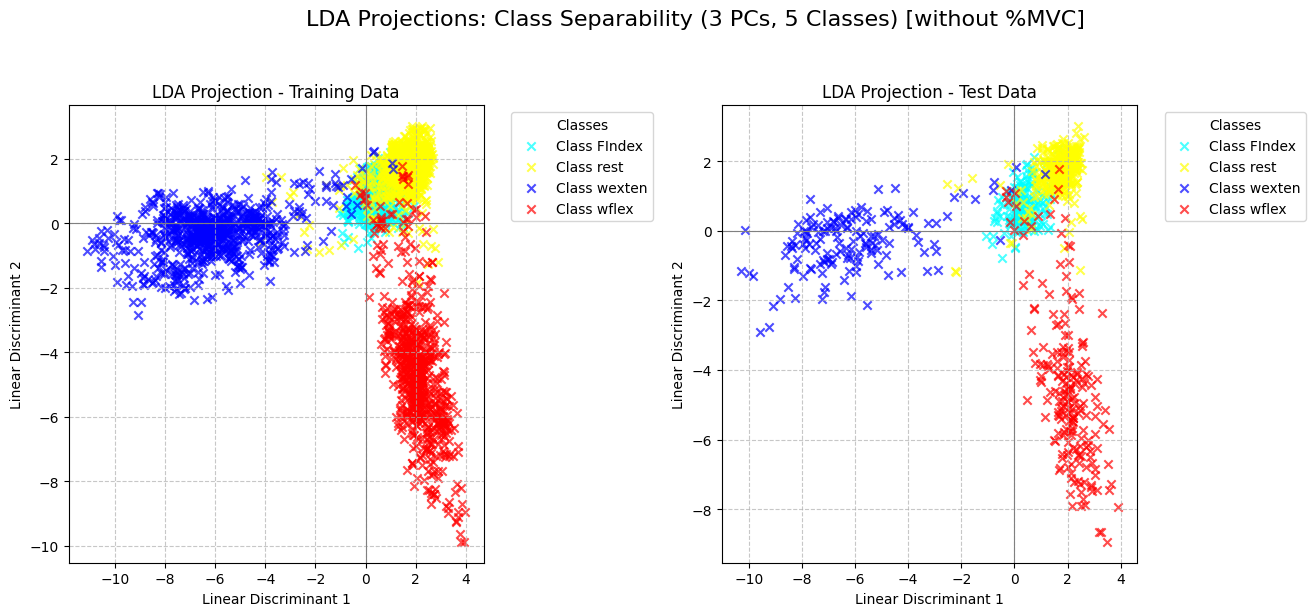

In [ ]:
print("Plotting 2D scatter plot using the first two Linear Discriminants.")

plt.figure(figsize=(14, 6))

# Plot Training Data
plt.subplot(1, 2, 1)
for i, class_label in enumerate(unique_classes):
    plt.scatter(X_train_lda[y_train == class_label, 0],
                X_train_lda[y_train == class_label, 1],
                alpha=0.7, color=colors[i], label=f'Class {class_label}', marker='x')
plt.title('LDA Projection - Training Data')
plt.xlabel('Linear Discriminant 1')
plt.ylabel('Linear Discriminant 2')
plt.legend(title='Classes', bbox_to_anchor=(1.05, 1), loc='upper left') # Legend outside plot
plt.grid(True, linestyle='--', alpha=0.7)
plt.axhline(0, color='gray', linewidth=0.8) # Add axes at zero for reference
plt.axvline(0, color='gray', linewidth=0.8)

# Plot Test Data
plt.subplot(1, 2, 2)
for i, class_label in enumerate(unique_classes):
    plt.scatter(X_test_lda[y_test == class_label, 0],
                X_test_lda[y_test == class_label, 1],
                alpha=0.7, color=colors[i], label=f'Class {class_label}', marker='x') # Use 'x' marker for test data
plt.title('LDA Projection - Test Data')
plt.xlabel('Linear Discriminant 1')
plt.ylabel('Linear Discriminant 2')
plt.legend(title='Classes', bbox_to_anchor=(1.05, 1), loc='upper left') # Legend outside plot
plt.grid(True, linestyle='--', alpha=0.7)
plt.axhline(0, color='gray', linewidth=0.8)
plt.axvline(0, color='gray', linewidth=0.8)

plt.suptitle('LDA Projections: Class Separability (3 PCs, 5 Classes) [without %MVC]', fontsize=16, y=1.02)
plt.tight_layout(rect=[0, 0, 0.95, 0.98]) # Adjust layout to make space for suptitle and side legend
plt.show()

In [ ]:
y_pred = lda.predict(X_pca_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy (LDA): {accuracy*100}")

Accuracy (LDA): 93.7952430196484


<Figure size 600x600 with 0 Axes>

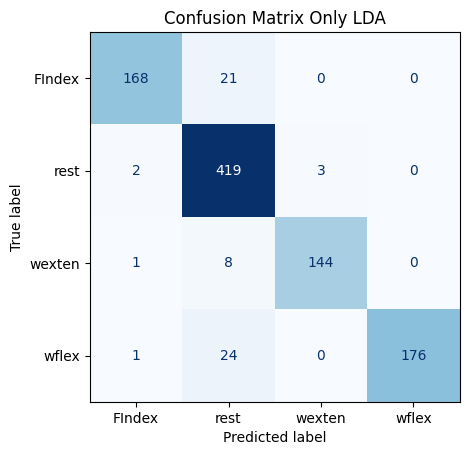

In [ ]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.unique(y_test))

# Plot
plt.figure(figsize=(6, 6))
disp.plot(cmap='Blues', colorbar=False)
plt.title("Confusion Matrix Only LDA")
plt.grid(False)
plt.show()

In [ ]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

      FIndex       0.98      0.89      0.93       189
        rest       0.89      0.99      0.94       424
      wexten       0.98      0.94      0.96       153
       wflex       1.00      0.88      0.93       201

    accuracy                           0.94       967
   macro avg       0.96      0.92      0.94       967
weighted avg       0.94      0.94      0.94       967



QDA

In [ ]:
qda  = QuadraticDiscriminantAnalysis()
qda.fit(X_pca, y_train)

e:\RTMC_NML_Public\Mindrove_venv\Mindrove_tf_env_311\Lib\site-packages\sklearn\discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
e:\RTMC_NML_Public\Mindrove_venv\Mindrove_tf_env_311\Lib\site-packages\sklearn\discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
e:\RTMC_NML_Public\Mindrove_venv\Mindrove_tf_env_311\Lib\site-packages\sklearn\discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 2 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
e:\RTMC_NML_Public\Mindrove_venv\Mindrove_tf_env_311\Lib\site-packages\sklearn\discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 3 is not full

QuadraticDiscriminantAnalysis()

In [ ]:
y_pred_qda = qda.predict(X_pca_test)
accuracy = accuracy_score(y_test, y_pred_qda)
print(f"Accuracy (QDA): {accuracy*100}")

Accuracy (QDA): 95.65667011375389


<Figure size 600x600 with 0 Axes>

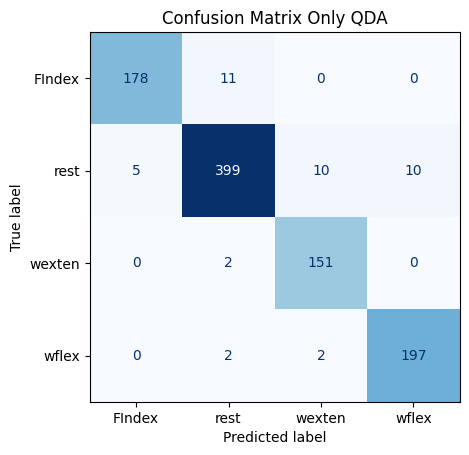

In [ ]:
cm = confusion_matrix(y_test, y_pred_qda)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.unique(y_test))

# Plot
plt.figure(figsize=(6, 6))
disp.plot(cmap='Blues', colorbar=False)
plt.title("Confusion Matrix Only QDA")
plt.grid(False)
plt.show()

Other Classifiers

In [ ]:
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

In [ ]:
classifiers = {
    'LDA' : LinearDiscriminantAnalysis(),
    'SVM (RBF Kernel)': SVC(kernel='rbf', C=1.0, gamma='scale'),
    'Random Forest': RandomForestClassifier(n_estimators=100),
    'k-NN': KNeighborsClassifier(n_neighbors=4),
    'MLP': MLPClassifier(hidden_layer_sizes=(100, 50), max_iter=300, random_state=42)
}

In [ ]:
results = []

In [ ]:
unique_classes = np.unique(y_train)
colors = [label_colors[label] for label in unique_classes]

              precision    recall  f1-score   support

      FIndex       0.98      0.89      0.93       189
        rest       0.89      0.99      0.94       424
      wexten       0.98      0.94      0.96       153
       wflex       1.00      0.88      0.93       201

    accuracy                           0.94       967
   macro avg       0.96      0.92      0.94       967
weighted avg       0.94      0.94      0.94       967



<Figure size 600x600 with 0 Axes>

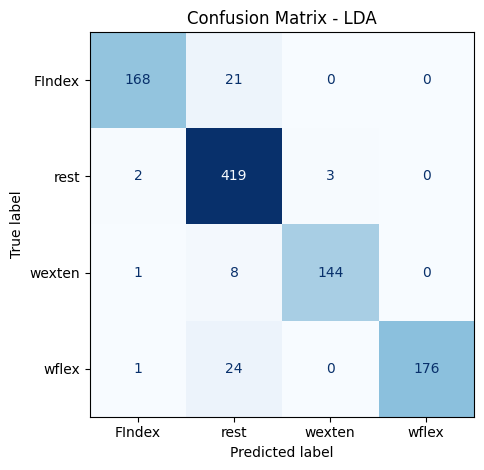

              precision    recall  f1-score   support

      FIndex       0.98      0.93      0.96       189
        rest       0.95      1.00      0.97       424
      wexten       1.00      0.98      0.99       153
       wflex       0.99      0.95      0.97       201

    accuracy                           0.97       967
   macro avg       0.98      0.96      0.97       967
weighted avg       0.97      0.97      0.97       967



<Figure size 600x600 with 0 Axes>

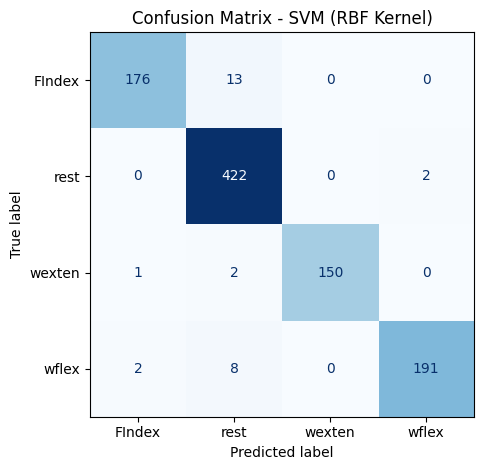

              precision    recall  f1-score   support

      FIndex       0.98      0.94      0.96       189
        rest       0.95      0.98      0.97       424
      wexten       0.97      0.99      0.98       153
       wflex       0.99      0.96      0.97       201

    accuracy                           0.97       967
   macro avg       0.97      0.97      0.97       967
weighted avg       0.97      0.97      0.97       967



<Figure size 600x600 with 0 Axes>

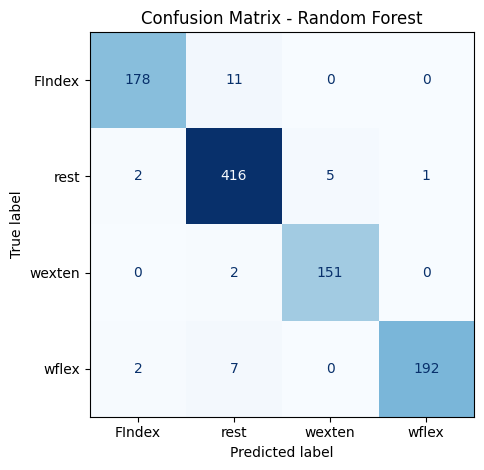

              precision    recall  f1-score   support

      FIndex       0.97      0.99      0.98       189
        rest       0.97      0.99      0.98       424
      wexten       1.00      0.97      0.99       153
       wflex       0.99      0.97      0.98       201

    accuracy                           0.98       967
   macro avg       0.98      0.98      0.98       967
weighted avg       0.98      0.98      0.98       967



<Figure size 600x600 with 0 Axes>

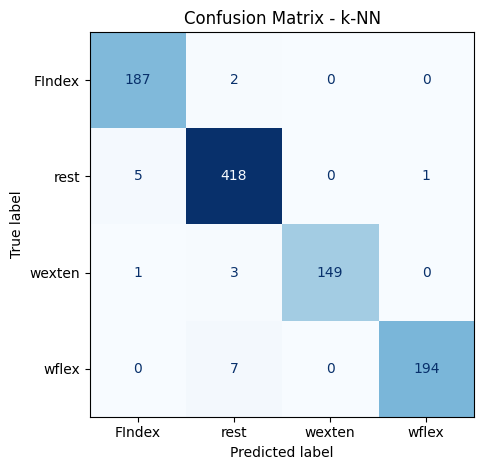

              precision    recall  f1-score   support

      FIndex       0.99      0.97      0.98       189
        rest       0.97      0.99      0.98       424
      wexten       0.99      0.97      0.98       153
       wflex       0.99      1.00      1.00       201

    accuracy                           0.98       967
   macro avg       0.99      0.98      0.98       967
weighted avg       0.98      0.98      0.98       967



<Figure size 600x600 with 0 Axes>

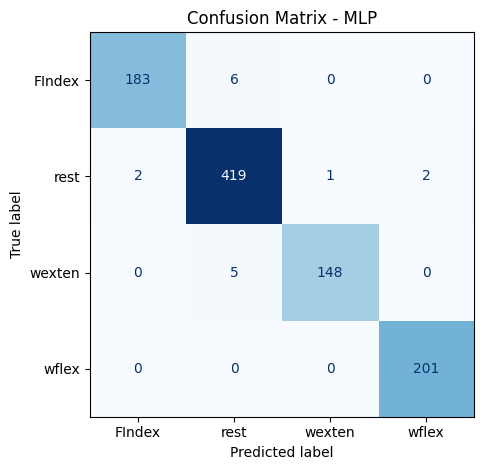

In [ ]:
for name, clf in classifiers.items():
    clf.fit(X_pca, y_train)
    y_pred_ = clf.predict(X_pca_test)
    acc = accuracy_score(y_test, y_pred_)
    cm = confusion_matrix(y_test, y_pred_)

    results.append({
        'name': name,
        'accuracy': acc,
        'confusion_matrix': cm
    })
    print(classification_report(y_test,y_pred_))
    # Plot confusion matrix
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=unique_classes)
    plt.figure(figsize=(6, 6))
    disp.plot(cmap='Blues', colorbar=False)
    plt.title(f"Confusion Matrix - {name}")
    plt.grid(False)
    plt.tight_layout()
    plt.show()

results_df = pd.DataFrame(results).drop(columns='confusion_matrix')

In [ ]:
print(results_df) # before

               name  accuracy
0               LDA  0.937952
1  SVM (RBF Kernel)  0.971044
2     Random Forest  0.968976
3              k-NN  0.980352
4               MLP  0.983454


Save Models

In [ ]:
import joblib
import datetime

In [ ]:
trained_classifiers = {
    # 'SVM_RBF': classifiers['SVM (RBF Kernel)'],
    # 'RandomForest': classifiers['Random Forest'],
    # 'kNN': classifiers['k-NN'],
    'MLP': classifiers['MLP']
}

In [ ]:
today_str = datetime.date.today().strftime("%Y_%m_%d")
participant = "data_2025_06_30_Dheemant_Jupyter"
actions =   "FLEX_EXTEN_INDEX" #"THUMB_INDEX_MIDDLE_RING_ISOMETRIC" # "FLEX_EXTEN_RADIAL_ULNAR"

In [ ]:
# for result in results:
#     clf_name = result['name'].replace(" ", "").replace("(", "").replace(")", "").replace("-", "")
#     accuracy_pct = int(result['accuracy'] * 100)
#     model = classifiers[result['name']]

#     filename = f"{clf_name}_{accuracy_pct}_{today_str}_{participant}_{actions}_0.pkl"
#     joblib.dump(model, filename)
#     print(f"Saved: {filename}")

Saved: LDA_93_2025_09_18_data_2025_06_30_Dheemant_Jupyter_FLEX_EXTEN_INDEX_0.pkl
Saved: SVMRBFKernel_97_2025_09_18_data_2025_06_30_Dheemant_Jupyter_FLEX_EXTEN_INDEX_0.pkl
Saved: RandomForest_96_2025_09_18_data_2025_06_30_Dheemant_Jupyter_FLEX_EXTEN_INDEX_0.pkl
Saved: kNN_98_2025_09_18_data_2025_06_30_Dheemant_Jupyter_FLEX_EXTEN_INDEX_0.pkl
Saved: MLP_98_2025_09_18_data_2025_06_30_Dheemant_Jupyter_FLEX_EXTEN_INDEX_0.pkl


In [ ]:
pca_save_path = f"PCA_{actions}_{participant}.pkl"
joblib.dump(pca, pca_save_path)
print(f"PCA model saved to: {pca_save_path}")

PCA model saved to: PCA_FLEX_EXTEN_INDEX_data_2025_06_30_Dheemant_Jupyter.pkl


LSTM Testing

In [ ]:
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import LSTM
from sklearn.metrics import mean_squared_error

Proportional Regression

In [ ]:
from sklearn.metrics import mean_squared_error
from sklearn.tree import DecisionTreeRegressor

In [ ]:
X_prop_feat = np.concatenate([X_rms, X_zc,X_ssc,X_wl], axis=1)
Y_prop_feat = X_mav

In [ ]:
X_prop_feat_train, X_prop_feat_test, Y_prop_feat_train, Y_prop_feat_test = train_test_split(X_prop_feat, Y_prop_feat, test_size=0.2, random_state=42)

In [ ]:
scaler_prop = StandardScaler()
scaler_prop.fit(X_prop_feat_train)
X_prop_feat_train = scaler_prop.transform(X_prop_feat_train)
X_prop_feat_test = scaler_prop.transform(X_prop_feat_test)
X_prop_feat_train = pd.DataFrame(X_prop_feat_train)
X_prop_feat_test = pd.DataFrame(X_prop_feat_test)

In [ ]:
tree_reg = DecisionTreeRegressor(max_depth=10, random_state=42)
tree_reg.fit(X_prop_feat_train, Y_prop_feat_train)
Y_prop_pred_train = tree_reg.predict(X_prop_feat_train)
Y_prop_pred_test = tree_reg.predict(X_prop_feat_test)

In [ ]:
mse_train = mean_squared_error(Y_prop_feat_train, Y_prop_pred_train)
mse_test = mean_squared_error(Y_prop_feat_test, Y_prop_pred_test)
print(f"Mean Squared Error (Decision Tree Regressor) - Train: {mse_train}, Test: {mse_test}")

Mean Squared Error (Decision Tree Regressor) - Train: 0.41259447152905293, Test: 1.4165685516112156


In [ ]:
linspace_test = np.linspace(0, len(Y_prop_feat_test), len(Y_prop_feat_test))
linspace_train = np.linspace(0, len(Y_prop_feat_train), len(Y_prop_feat_train))


In [ ]:
len(Y_prop_feat_train), len(linspace_train)

(3866, 3866)

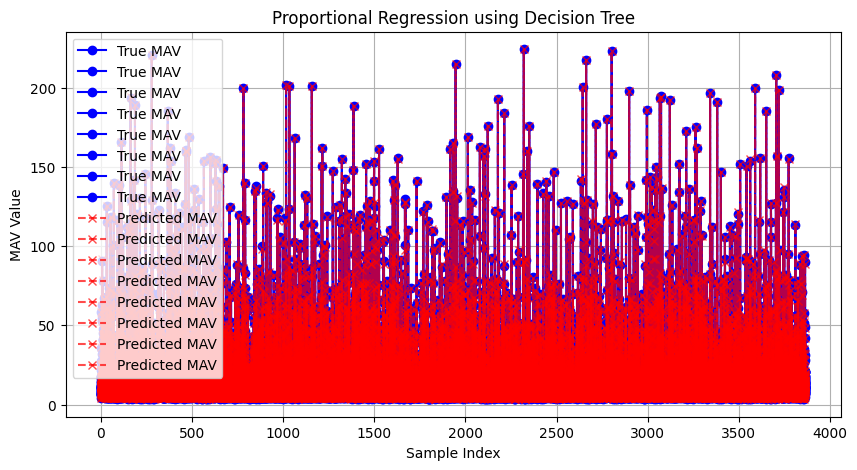

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(Y_prop_feat_train, label='True MAV', color='blue', marker='o')
plt.plot(Y_prop_pred_train, label='Predicted MAV', color='red', marker='x', linestyle='--', alpha=0.7)
plt.title('Proportional Regression using Decision Tree')
plt.xlabel('Sample Index')
plt.ylabel('MAV Value')
plt.legend()
plt.grid(True)

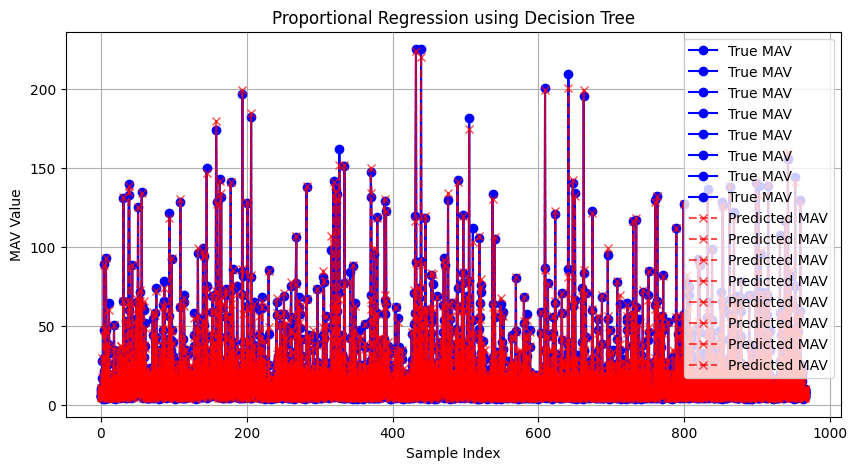

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(Y_prop_feat_test, label='True MAV', color='blue', marker='o')
plt.plot(Y_prop_pred_test, label='Predicted MAV', color='red', linestyle='--', marker='x', alpha=0.7)
plt.title('Proportional Regression using Decision Tree')
plt.xlabel('Sample Index')
plt.ylabel('MAV Value')
plt.legend()
plt.grid(True)

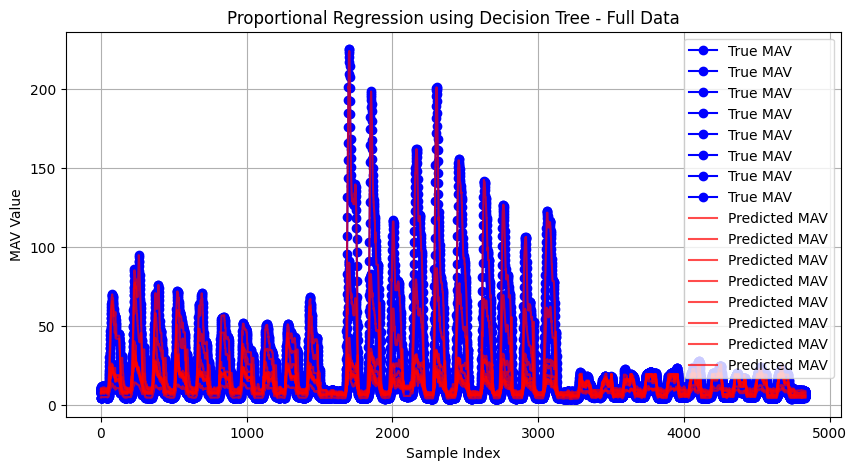

In [ ]:
X_prop_feat_scaled = scaler_prop.transform(X_prop_feat)
X_prop_feat_scaled = pd.DataFrame(X_prop_feat_scaled)
full_pred = tree_reg.predict(X_prop_feat_scaled)
plt.figure(figsize=(10, 5))
plt.plot(Y_prop_feat, label='True MAV', color='blue', marker='o')
plt.plot(full_pred, label='Predicted MAV', color='red', alpha=0.7)
plt.title('Proportional Regression using Decision Tree - Full Data')
plt.xlabel('Sample Index')
plt.ylabel('MAV Value')
plt.legend()
plt.grid(True)

In [ ]:
Y_prop_feat.shape

(4833, 8)

REAL-TIME PLOTTING ACCURACY (Testing)

In [ ]:
import pandas as pd
import os
import joblib
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, confusion_matrix
import seaborn as sns

In [ ]:
ml_model_path = "E:\RTMC_NML_Public\MLP_97_data_2025_09_24_DEF_P6_wflex_wexten_findex_0.pkl"

In [ ]:
full_window_df = pd.read_csv("E:\RTMC_NML_Public\Mindrove_venv\Data\P3_DEV\Online\data_2025_09_23_DEV_P3_MLP_Full_Window_0_full_window_log.csv")
full_window_df

,Ch1,Ch2,Ch3,Ch4,Ch5,Ch6,Ch7,Ch8,Label,Gesture,Stimulus
0,0.249134,0.177744,0.248262,0.599232,0.777170,0.579004,0.026096,0.336608,rest,rest,rest
1,-3.609796,-4.128085,-2.577830,-3.933852,-5.442491,-5.117141,-2.843596,-1.574495,rest,rest,rest
2,-0.795599,-1.901144,0.690484,-0.404945,-0.718360,-2.667883,-1.099933,0.648060,rest,rest,rest
3,-3.069273,-3.267422,-1.922210,1.214954,1.293771,-0.509692,0.955790,-0.437245,rest,rest,rest
4,-4.235662,-3.560983,-3.318214,0.943749,6.489192,1.253078,0.795425,-1.760036,rest,rest,rest
...,...,...,...,...,...,...,...,...,...,...,...
1130195,-7.309638,-5.954330,-4.429895,-14.932059,-9.396669,9.925281,4.711998,-1.258702,rest,NaN,complete
1130196,6.370864,6.139526,6.664807,12.803578,24.382529,6.718003,-1.435503,1.551683,rest,NaN,complete
1130197,19.121080,16.747285,16.733152,27.692930,3.557634,-10.547208,-5.369295,7.977565,rest,NaN,complete
1130198,13.848281,9.948333,9.607111,9.070825,1.098523,-2.876712,-1.254721,4.862862,rest,NaN,complete


In [ ]:
full_window_df['Stimulus'].unique()

array(['rest', 'up', 'hold', 'down', 'complete'], dtype=object)

In [ ]:
full_window_df = full_window_df[full_window_df['Stimulus'] != 'complete']
full_window_df

,Ch1,Ch2,Ch3,Ch4,Ch5,Ch6,Ch7,Ch8,Label,Gesture,Stimulus
0,0.249134,0.177744,0.248262,0.599232,0.777170,0.579004,0.026096,0.336608,rest,rest,rest
1,-3.609796,-4.128085,-2.577830,-3.933852,-5.442491,-5.117141,-2.843596,-1.574495,rest,rest,rest
2,-0.795599,-1.901144,0.690484,-0.404945,-0.718360,-2.667883,-1.099933,0.648060,rest,rest,rest
3,-3.069273,-3.267422,-1.922210,1.214954,1.293771,-0.509692,0.955790,-0.437245,rest,rest,rest
4,-4.235662,-3.560983,-3.318214,0.943749,6.489192,1.253078,0.795425,-1.760036,rest,rest,rest
...,...,...,...,...,...,...,...,...,...,...,...
1117395,5.616046,8.481287,10.605814,33.696785,37.930956,6.098511,-3.533913,-0.433197,wflex,findex,down
1117396,2.591313,6.706590,9.131668,4.121958,17.668786,4.114804,-3.663728,-1.379501,wflex,findex,down
1117397,21.938373,25.848335,25.676273,40.250259,41.350010,12.086660,-3.250588,3.166219,wflex,findex,down
1117398,11.770874,15.411468,17.507860,63.926711,53.115495,20.432782,3.528503,0.661975,wflex,findex,down


In [ ]:
full_window_df.shape

(1117400, 11)

In [ ]:
full_window_df['Label'].unique()

array(['rest', 'wexten', 'wflex', 'findex'], dtype=object)

In [ ]:
full_window_df = full_window_df[full_window_df['Stimulus'] != 'complete']
full_window_df['Gesture'].fillna('rest')
full_window_df['Label'].fillna('rest')

0           rest
1           rest
2           rest
3           rest
4           rest
           ...  
1117395    wflex
1117396    wflex
1117397    wflex
1117398    wflex
1117399    wflex
Name: Label, Length: 1117400, dtype: object

In [ ]:
full_window_df['Gesture'].unique()

array(['rest', 'wflex', 'wexten', 'findex'], dtype=object)

In [ ]:
full_window_df

,Ch1,Ch2,Ch3,Ch4,Ch5,Ch6,Ch7,Ch8,Label,Gesture,Stimulus
0,0.249134,0.177744,0.248262,0.599232,0.777170,0.579004,0.026096,0.336608,rest,rest,rest
1,-3.609796,-4.128085,-2.577830,-3.933852,-5.442491,-5.117141,-2.843596,-1.574495,rest,rest,rest
2,-0.795599,-1.901144,0.690484,-0.404945,-0.718360,-2.667883,-1.099933,0.648060,rest,rest,rest
3,-3.069273,-3.267422,-1.922210,1.214954,1.293771,-0.509692,0.955790,-0.437245,rest,rest,rest
4,-4.235662,-3.560983,-3.318214,0.943749,6.489192,1.253078,0.795425,-1.760036,rest,rest,rest
...,...,...,...,...,...,...,...,...,...,...,...
1117395,5.616046,8.481287,10.605814,33.696785,37.930956,6.098511,-3.533913,-0.433197,wflex,findex,down
1117396,2.591313,6.706590,9.131668,4.121958,17.668786,4.114804,-3.663728,-1.379501,wflex,findex,down
1117397,21.938373,25.848335,25.676273,40.250259,41.350010,12.086660,-3.250588,3.166219,wflex,findex,down
1117398,11.770874,15.411468,17.507860,63.926711,53.115495,20.432782,3.528503,0.661975,wflex,findex,down


In [ ]:
num_channels = 8
ground_truth_labels = full_window_df['Gesture'].values
# predicted_labels = full_window_df['Label'].values
filtered_emg_data = full_window_df.iloc[:, :num_channels].values

In [ ]:
filtered_emg_data.shape, ground_truth_labels.shape

((1117400, 8), (1117400,))

In [ ]:
def compute_rms(windows):
    return np.sqrt(np.mean(np.square(windows), axis=0))

In [ ]:
def mean_absolute_value(data):
    # Average absolute value across time
    return np.mean(np.abs(data), axis=0)  # (num_channels,)

def count_zero_crossings_diff(data, threshold=0.01):
    # Zero crossings per channel
    zero_crossings = ((data[:-1] * data[1:]) < 0) & (np.abs(data[:-1] - data[1:]) > threshold)
    return np.sum(zero_crossings, axis=0)  # (num_channels,)

def slope_sign_changes(data, threshold=0.01):
    diff1 = np.diff(data, n=1, axis=0)
    ssc = (((diff1[:-1] * diff1[1:]) < 0) &
           (np.abs(diff1[:-1] - diff1[1:]) > threshold))
    return np.sum(ssc, axis=0)  # (num_channels,)

def waveform_length(data):
    return np.sum(np.abs(np.diff(data, axis=0)), axis=0)  # (num_channels,)


In [ ]:
def sliding_window_RT_1_4_all(df, ml_model_path, ground_truth, window_size=200, stride=20, num_channels=8, buffer_size=300):
    # Load model
    model_bundle = joblib.load(ml_model_path)
    ml_model = model_bundle['ML_model']
    scaler_model = model_bundle['scaler_model']
    pca_model = model_bundle['pca_model']

    ground_truth = ground_truth.to_numpy()
    pred, gt = [], []

    # Preprocess: rectified signals (no smoothing here - will be done per buffer)
    rectified_signals = []
    for i in range(num_channels):
        emg = df.iloc[:, i].values
        rectified = np.abs(emg)
        rectified_signals.append(rectified)

    rectified_signals = pd.DataFrame(rectified_signals).T
    filtered_signals = df.iloc[:, :num_channels]

    # Sliding buffer approach - smoothing applied to each buffer
    for buffer_start in range(buffer_size, filtered_signals.shape[0] + 1, stride):
        # Get current buffer (last buffer_size samples)
        buffer_end = buffer_start
        buffer_begin = buffer_start - buffer_size

        # Extract buffer data
        filtered_buffer = filtered_signals.iloc[buffer_begin:buffer_end, :]
        rectified_buffer = rectified_signals.iloc[buffer_begin:buffer_end, :]

        # Apply smoothing to the entire buffer for each channel
        smoothed_buffer = []
        for ch in range(num_channels):
            rectified_ch = rectified_buffer.iloc[:, ch].values
            smoothed_ch = moving_window_rms(rectified_ch, window_size)  # Apply to entire buffer
            smoothed_buffer.append(smoothed_ch)

        smoothed_buffer = pd.DataFrame(smoothed_buffer).T

        # Extract windows from the smoothed buffer
        # Note: You might need to adjust this based on how many windows you want from each buffer
        # For now, taking one window from the end of the buffer to match your stride
        win_start = buffer_size - window_size  # Start of window within buffer
        win_end = buffer_size  # End of window within buffer

        filtered_win = np.array(filtered_buffer.iloc[win_start:win_end, :])
        rectified_win = np.array(rectified_buffer.iloc[win_start:win_end, :])
        smoothed_win = np.array(smoothed_buffer.iloc[win_start:win_end, :])

        # Features (each returns num_channels-long vector)
        X_rms = compute_rms(smoothed_win)                  # shape (8,)
        X_mav = mean_absolute_value(smoothed_win)          # shape (8,)
        X_zc = count_zero_crossings_diff(filtered_win)     # shape (8,)
        X_ssc = slope_sign_changes(rectified_win)          # shape (8,)
        X_wl = waveform_length(smoothed_win)               # shape (8,)

        # Concatenate
        X_features = np.concatenate([X_rms, X_mav, X_zc, X_ssc, X_wl], axis=0).reshape(1, -1)

        # Normalize + PCA + predict
        normalized_X = scaler_model.transform(X_features)
        pca_X = pca_model.transform(normalized_X)
        label = ml_model.predict(pca_X)

        # Majority ground truth label for window
        # Adjust indices to match the actual signal position
        signal_win_start = buffer_start - window_size
        signal_win_end = buffer_start
        g_label = max_labels(ground_truth[signal_win_start:signal_win_end])
        gt.append(g_label)
        pred.append(label)


    return np.array(pred), np.array(gt)

In [ ]:
# def sliding_window_RT(df, labels, ground_truth, window_size=200, stride=200, num_channels=8): # Works one-to-one testing.. for predicted to ground truth labels in the csv
#     signal = df.iloc[:, :num_channels].to_numpy()
#     labels = labels.to_numpy()
#     ground_truth = ground_truth.to_numpy()
#     pred, gt = [], []
#     rms_signals = []

#     for i in range(0, len(signal) - window_size + 1, stride):
#         win = signal[i:i+window_size]

#         label = max_labels(labels[i:i+window_size])
#         g_label = max_labels(ground_truth[i:i+window_size])
#         gt.append(g_label)
#         pred.append(label)
#     return np.array(pred), np.array(gt)

In [ ]:
pred, gt_label = sliding_window_RT_1_4_all(full_window_df, ml_model_path, full_window_df['Gesture'], window_size=200, stride=200)

In [ ]:
gt_label.shape, pred.shape

((5586,), (5586,))

In [ ]:
pred

array(['rest', 'rest', 'rest', ..., 'rest', 'rest', 'rest'], dtype='<U6')

In [ ]:
gt_label = pd.DataFrame(gt_label)
gt_label.fillna('rest')

,0
0,rest
1,rest
2,rest
3,rest
4,rest
...,...
5581,findex
5582,findex
5583,findex
5584,findex


In [ ]:
from sklearn.metrics import accuracy_score

pred = np.array(pred).ravel()
gt_label = np.array(gt_label).ravel()

accuracy = accuracy_score(pred,gt_label)
print(f"Accuracy: {accuracy*100:.2f}%")


Accuracy: 77.03%


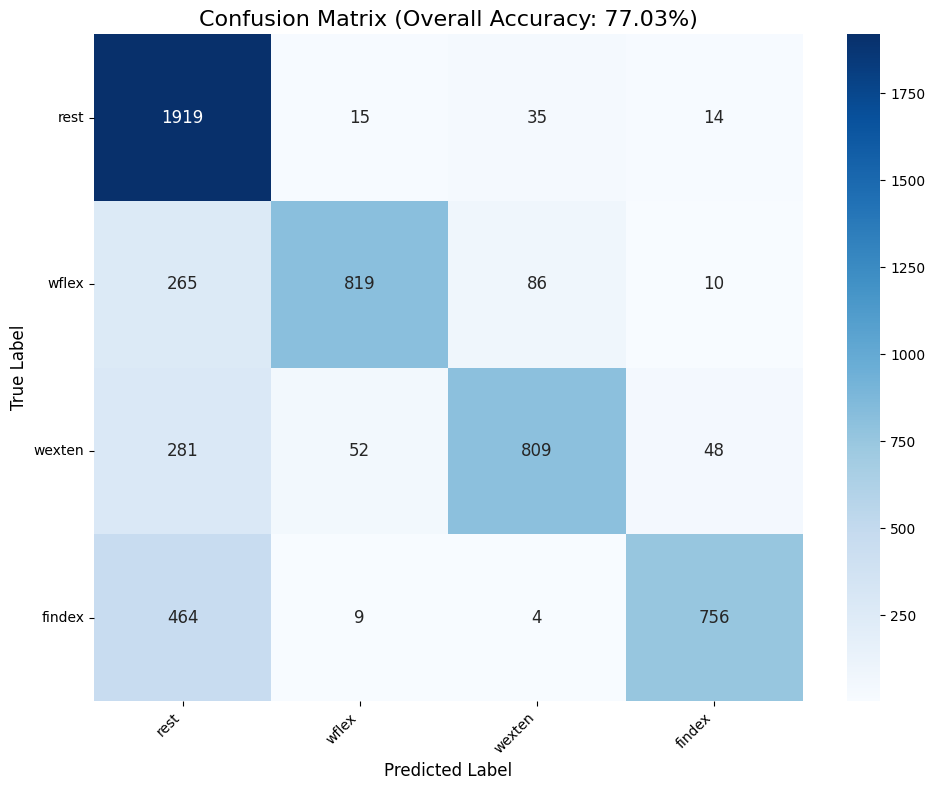

In [ ]:
unique_gestures = ['rest', 'wflex', 'wexten', 'findex']
cm = confusion_matrix(gt_label, pred, labels=unique_gestures)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=unique_gestures, yticklabels=unique_gestures, annot_kws={"size": 12})
plt.title(f'Confusion Matrix (Overall Accuracy: {accuracy:.2%})', fontsize=16)
plt.ylabel('True Label', fontsize=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

With Adjustment:

In [ ]:
def sliding_window_RT_1_4_all_with_adjustment(df, ml_model_path, ground_truth, window_size=200, stride=20, num_channels=8, buffer_size=300):
    # Load model
    model_bundle = joblib.load(ml_model_path)
    ml_model = model_bundle['ML_model']
    scaler_model = model_bundle['scaler_model']
    pca_model = model_bundle['pca_model']

    ground_truth = ground_truth.to_numpy()
    pred, gt = [], []
    window_means = []  # Store mean values for each window
    window_positions = []  # Store window positions for debugging

    # Preprocess: rectified signals (no smoothing here - will be done per buffer)
    rectified_signals = []
    for i in range(num_channels):
        emg = df.iloc[:, i].values
        rectified = np.abs(emg)
        rectified_signals.append(rectified)

    rectified_signals = pd.DataFrame(rectified_signals).T
    filtered_signals = df.iloc[:, :num_channels]

    # Sliding buffer approach - smoothing applied to each buffer
    for buffer_start in range(buffer_size, filtered_signals.shape[0] + 1, stride):
        # Get current buffer (last buffer_size samples)
        buffer_end = buffer_start
        buffer_begin = buffer_start - buffer_size

        # Extract buffer data
        filtered_buffer = filtered_signals.iloc[buffer_begin:buffer_end, :]
        rectified_buffer = rectified_signals.iloc[buffer_begin:buffer_end, :]

        # Apply smoothing to the entire buffer for each channel
        smoothed_buffer = []
        for ch in range(num_channels):
            rectified_ch = rectified_buffer.iloc[:, ch].values
            smoothed_ch = moving_window_rms(rectified_ch, window_size)  # Apply to entire buffer
            smoothed_buffer.append(smoothed_ch)

        smoothed_buffer = pd.DataFrame(smoothed_buffer).T

        # Extract windows from the smoothed buffer
        win_start = buffer_size - window_size  # Start of window within buffer
        win_end = buffer_size  # End of window within buffer

        filtered_win = np.array(filtered_buffer.iloc[win_start:win_end, :])
        rectified_win = np.array(rectified_buffer.iloc[win_start:win_end, :])
        smoothed_win = np.array(smoothed_buffer.iloc[win_start:win_end, :])

        # Calculate mean amplitude for this window (across all channels)
        window_mean = np.mean(smoothed_win)
        window_means.append(window_mean)

        # Store window position for reference
        signal_win_start = buffer_start - window_size
        signal_win_end = buffer_start
        window_positions.append((signal_win_start, signal_win_end))

        # Features (each returns num_channels-long vector)
        X_rms = compute_rms(smoothed_win)                  # shape (8,)
        X_mav = mean_absolute_value(smoothed_win)          # shape (8,)
        X_zc = count_zero_crossings_diff(filtered_win)     # shape (8,)
        X_ssc = slope_sign_changes(rectified_win)          # shape (8,)
        X_wl = waveform_length(smoothed_win)               # shape (8,)

        # Concatenate
        X_features = np.concatenate([X_rms, X_mav, X_zc, X_ssc, X_wl], axis=0).reshape(1, -1)

        # Normalize + PCA + predict
        normalized_X = scaler_model.transform(X_features)
        pca_X = pca_model.transform(normalized_X)
        label = ml_model.predict(pca_X)[0]  # Get single prediction

        # Majority ground truth label for window
        g_label = max_labels(ground_truth[signal_win_start:signal_win_end])
        gt.append(g_label)
        pred.append(label)

    # Convert to arrays
    pred = np.array(pred)
    gt = np.array(gt)
    window_means = np.array(window_means)

    # Post-process: Re-adjust ground truth labels
    pred_adjusted, gt_adjusted = post_process_rest_predictions(
        pred, gt, window_means, ground_truth, window_positions
    )

    return pred_adjusted, gt_adjusted

def post_process_rest_predictions(pred, gt, window_means, full_ground_truth, window_positions):
    """
    Re-adjust ground truth labels when prediction is 'rest' but true label is not 'rest'
    based on signal amplitude comparison with actual rest samples.
    """
    # Find all windows where ground truth is 'rest'
    rest_mask = (gt == 'rest')

    if np.sum(rest_mask) == 0:
        print("Warning: No rest samples found in ground truth")
        return pred, gt

    # Calculate threshold based on rest samples
    rest_means = window_means[rest_mask]
    rest_threshold = np.mean(rest_means) + np.std(rest_means)  # Mean + std

    print(f"Rest samples statistics:")
    print(f"  Mean amplitude: {np.mean(rest_means):.4f}")
    print(f"  Std amplitude: {np.std(rest_means):.4f}")
    print(f"  Threshold: {rest_threshold:.4f}")

    # Find cases where prediction is 'rest' but true label is not 'rest'
    adjustment_mask = (pred == 'rest') & (gt != 'rest')

    print(f"\nFound {np.sum(adjustment_mask)} windows with pred='rest' and gt!='rest'")

    # Make copies for adjustment
    gt_adjusted = gt.copy()
    pred_adjusted = pred.copy()

    adjustments_made = 0

    for i in range(len(pred)):
        if adjustment_mask[i]:
            current_mean = window_means[i]
            current_gt = gt[i]

            # If the window mean is greater than rest threshold, keep the original ground truth
            if current_mean > rest_threshold:
                # Keep the original ground truth (it's likely a real gesture)
                print(f"Window {i}: Mean {current_mean:.4f} > threshold {rest_threshold:.4f}, "
                      f"keeping GT as '{current_gt}'")
                adjustments_made += 1
            else:
                # The signal is actually rest-like, adjust ground truth to 'rest'
                gt_adjusted[i] = 'rest'
                print(f"Window {i}: Mean {current_mean:.4f} <= threshold {rest_threshold:.4f}, "
                      f"adjusting GT from '{current_gt}' to 'rest'")

    print(f"\nTotal adjustments made: {adjustments_made}")
    print(f"Ground truth labels changed to 'rest': {np.sum(adjustment_mask) - adjustments_made}")

    return pred_adjusted, gt_adjusted


In [ ]:
full_window_df = pd.read_csv("E:\RTMC_NML_Public\Mindrove_venv\Data\P7_DHE\Online\data_2025_09_25_DHE_P7_Full_Window_0_full_window_log.csv")
full_window_df

,Ch1,Ch2,Ch3,Ch4,Ch5,Ch6,Ch7,Ch8,Label,Gesture,Stimulus
0,0.704416,2.086037,3.087952,4.074895,3.200699,3.603504,-1.632969,0.778319,rest,rest,rest
1,-6.278287,-4.499566,-2.396360,-0.345770,0.762618,2.059931,-4.024869,-4.299531,rest,rest,rest
2,-3.061286,-4.248654,-3.689165,-0.778006,0.544521,2.862534,-2.775911,-1.116063,rest,rest,rest
3,-0.731714,-0.876473,-0.255356,2.111420,2.791366,5.638329,-5.370341,0.801397,rest,rest,rest
4,-3.405604,-1.983633,0.921868,4.213572,4.227105,7.378535,-7.164377,-0.079628,rest,rest,rest
...,...,...,...,...,...,...,...,...,...,...,...
1162795,-2.997568,-6.831498,-8.232898,-3.494115,-0.163809,-0.028323,0.658465,-3.961684,rest,NaN,complete
1162796,1.040875,-7.225573,-10.534609,-6.909090,-3.298049,-1.359622,-1.414383,-2.769236,rest,NaN,complete
1162797,1.907988,-6.909529,-10.918415,-8.052431,-2.687847,2.117445,3.895696,3.192551,rest,NaN,complete
1162798,-4.441373,-3.934889,-7.138080,-7.248969,-1.310565,3.265626,4.025849,-1.120708,rest,NaN,complete


In [ ]:
full_window_df = full_window_df[full_window_df['Stimulus'] != 'complete']
full_window_df['Gesture'].fillna('rest')
full_window_df['Label'].fillna('rest')

0          rest
1          rest
2          rest
3          rest
4          rest
           ... 
1137195    rest
1137196    rest
1137197    rest
1137198    rest
1137199    rest
Name: Label, Length: 1137200, dtype: object

Rest samples statistics:
  Mean amplitude: 7.0354
  Std amplitude: 5.5755
  Threshold: 12.6109

Found 1030 windows with pred='rest' and gt!='rest'
Window 176: Mean 4.0267 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 177: Mean 4.1095 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 178: Mean 3.8988 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 179: Mean 4.1600 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 180: Mean 4.1097 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 181: Mean 4.1298 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 182: Mean 4.2225 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 183: Mean 3.9478 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 184: Mean 3.8217 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 185: Mean 3.9153 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 186: Mean 4.2084 <= thresh

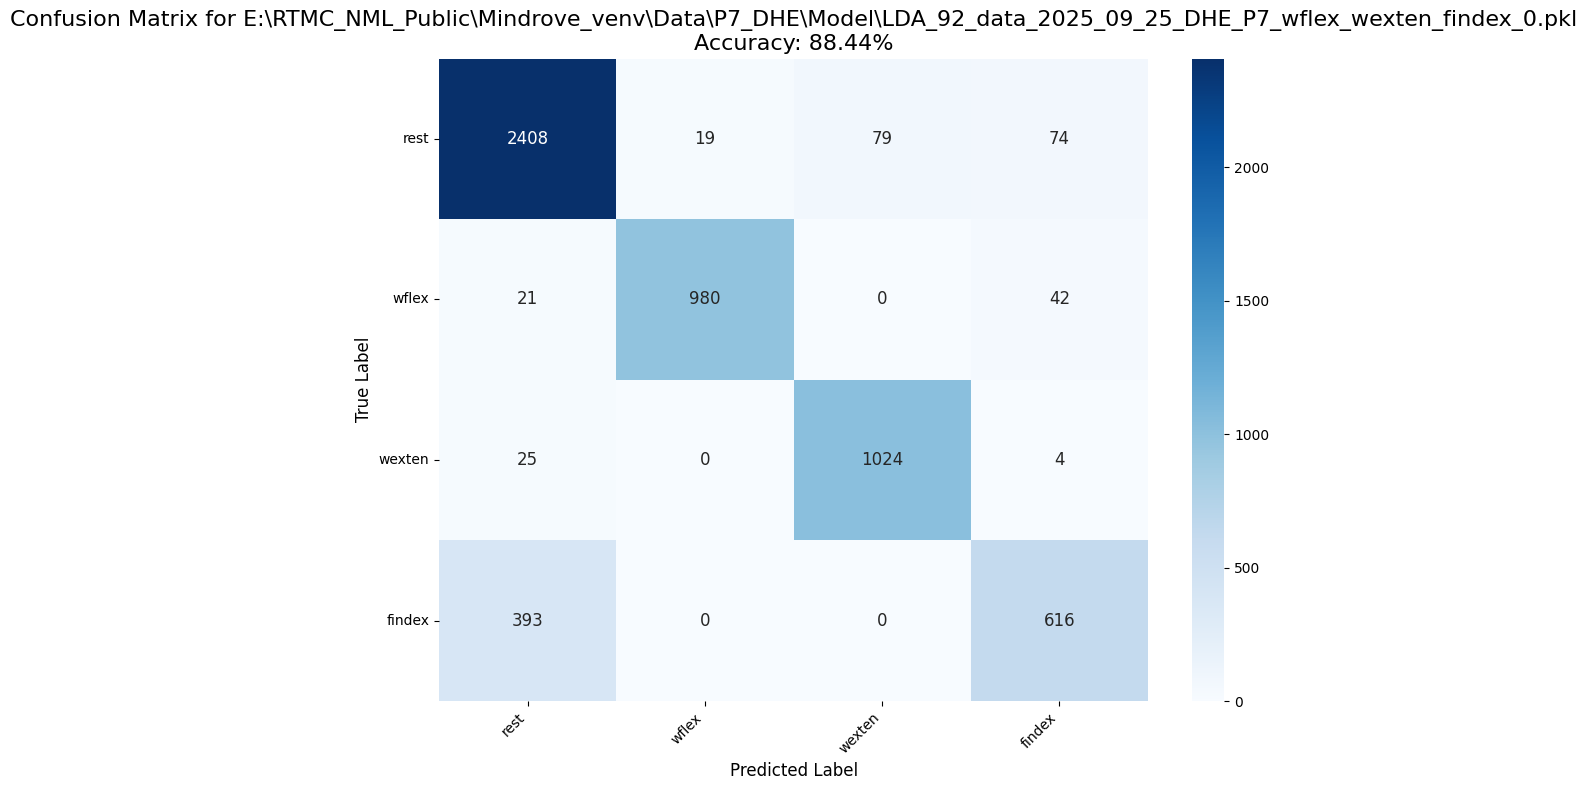

C:\Users\dheem\AppData\Local\Temp\ipykernel_5456\109475387.py:74: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=unique_gestures, y=f1_scores, palette="viridis")


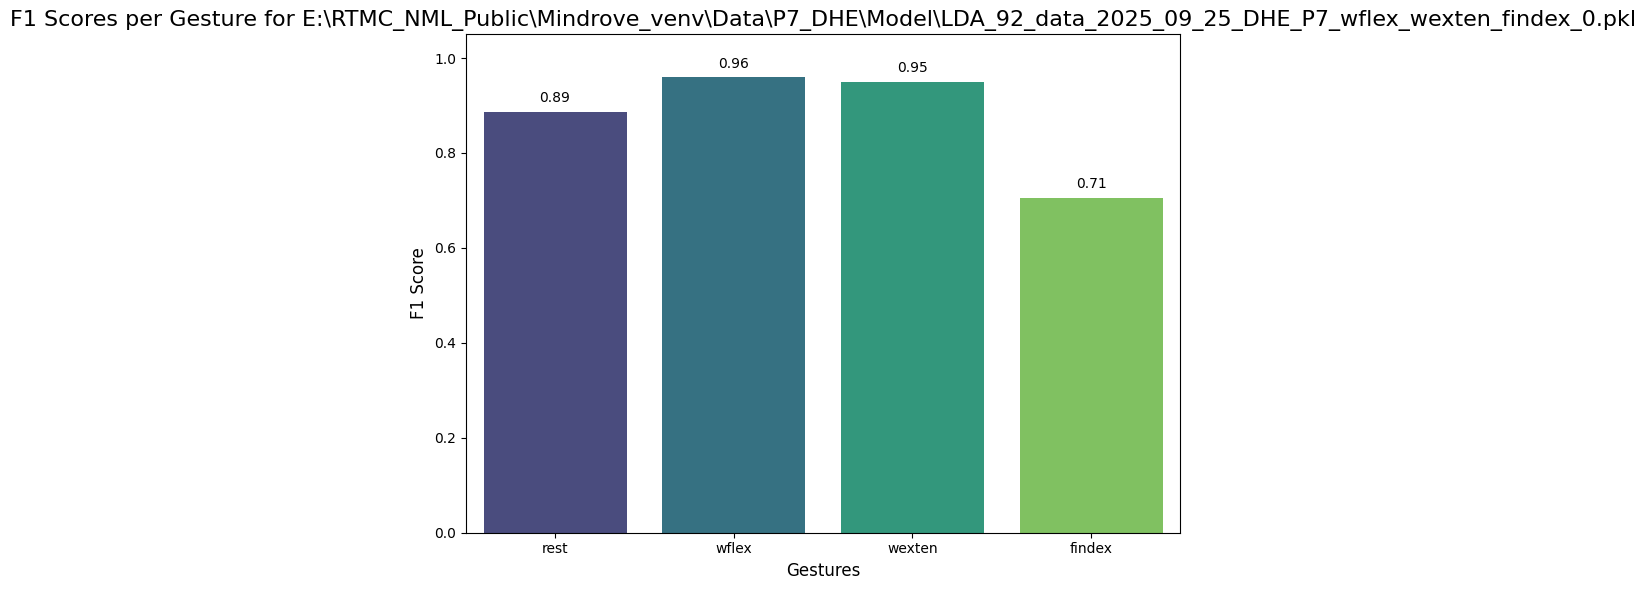

Rest samples statistics:
  Mean amplitude: 7.0354
  Std amplitude: 5.5755
  Threshold: 12.6109

Found 725 windows with pred='rest' and gt!='rest'
Window 176: Mean 4.0267 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 177: Mean 4.1095 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 178: Mean 3.8988 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 179: Mean 4.1600 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 180: Mean 4.1097 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 181: Mean 4.1298 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 182: Mean 4.2225 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 183: Mean 3.9478 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 184: Mean 3.8217 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 185: Mean 3.9153 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 186: Mean 4.2084 <= thresho

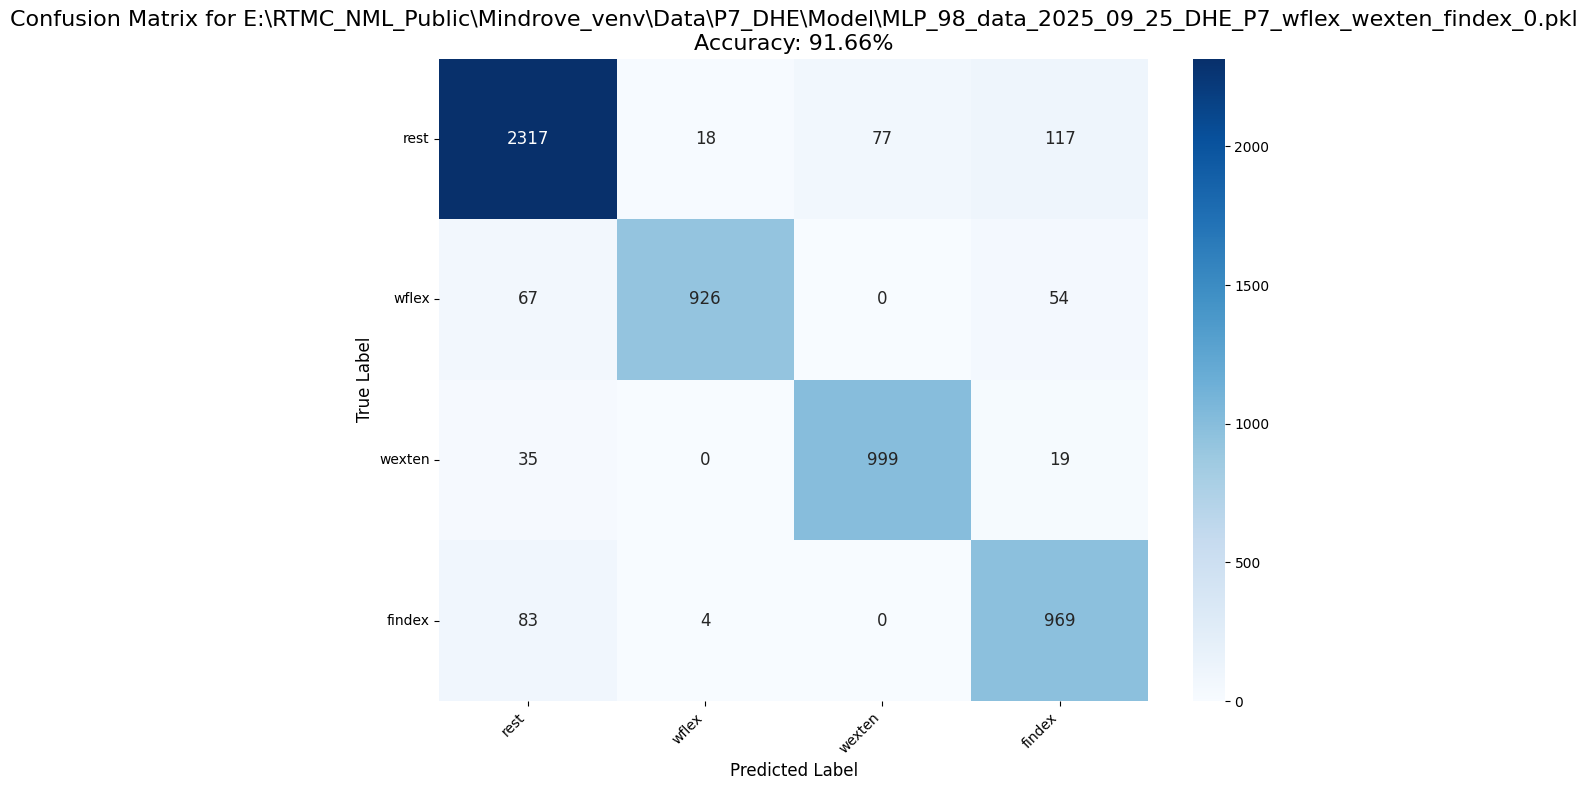

C:\Users\dheem\AppData\Local\Temp\ipykernel_5456\109475387.py:74: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=unique_gestures, y=f1_scores, palette="viridis")


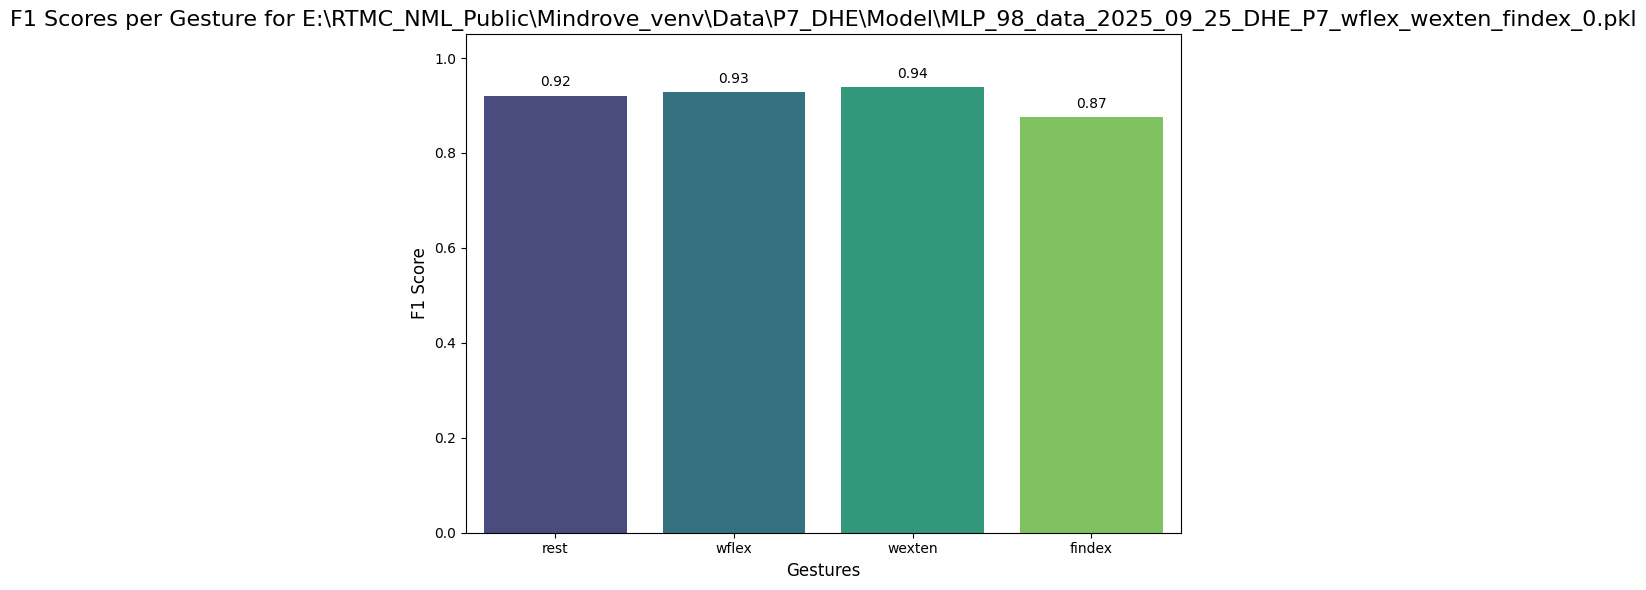

Rest samples statistics:
  Mean amplitude: 7.0354
  Std amplitude: 5.5755
  Threshold: 12.6109

Found 584 windows with pred='rest' and gt!='rest'
Window 176: Mean 4.0267 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 177: Mean 4.1095 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 178: Mean 3.8988 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 179: Mean 4.1600 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 180: Mean 4.1097 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 181: Mean 4.1298 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 182: Mean 4.2225 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 183: Mean 3.9478 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 184: Mean 3.8217 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 185: Mean 3.9153 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 186: Mean 4.2084 <= thresho

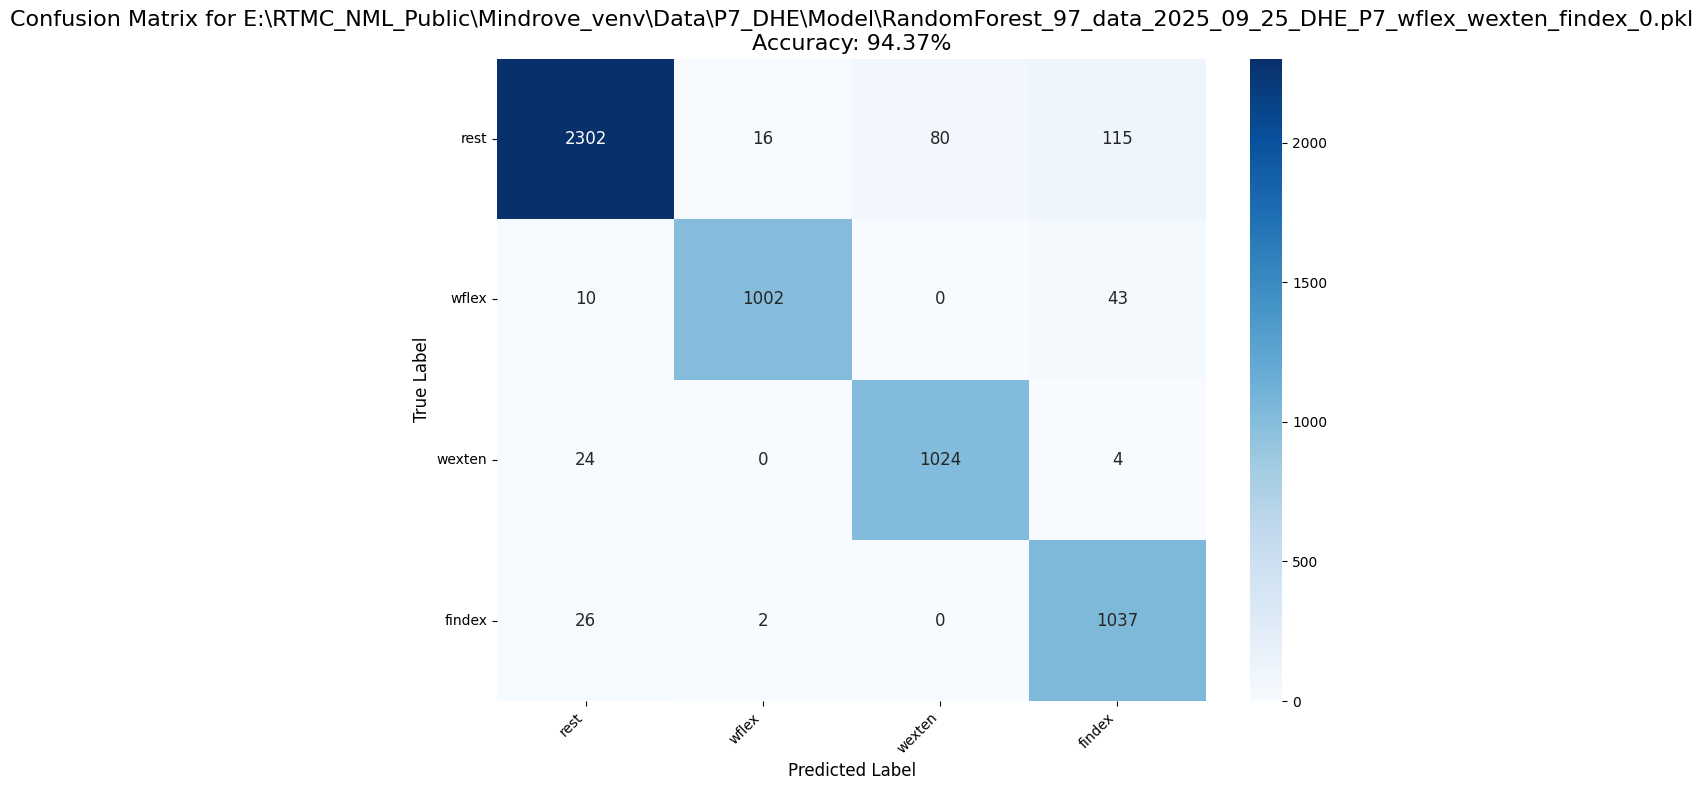

C:\Users\dheem\AppData\Local\Temp\ipykernel_5456\109475387.py:74: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=unique_gestures, y=f1_scores, palette="viridis")


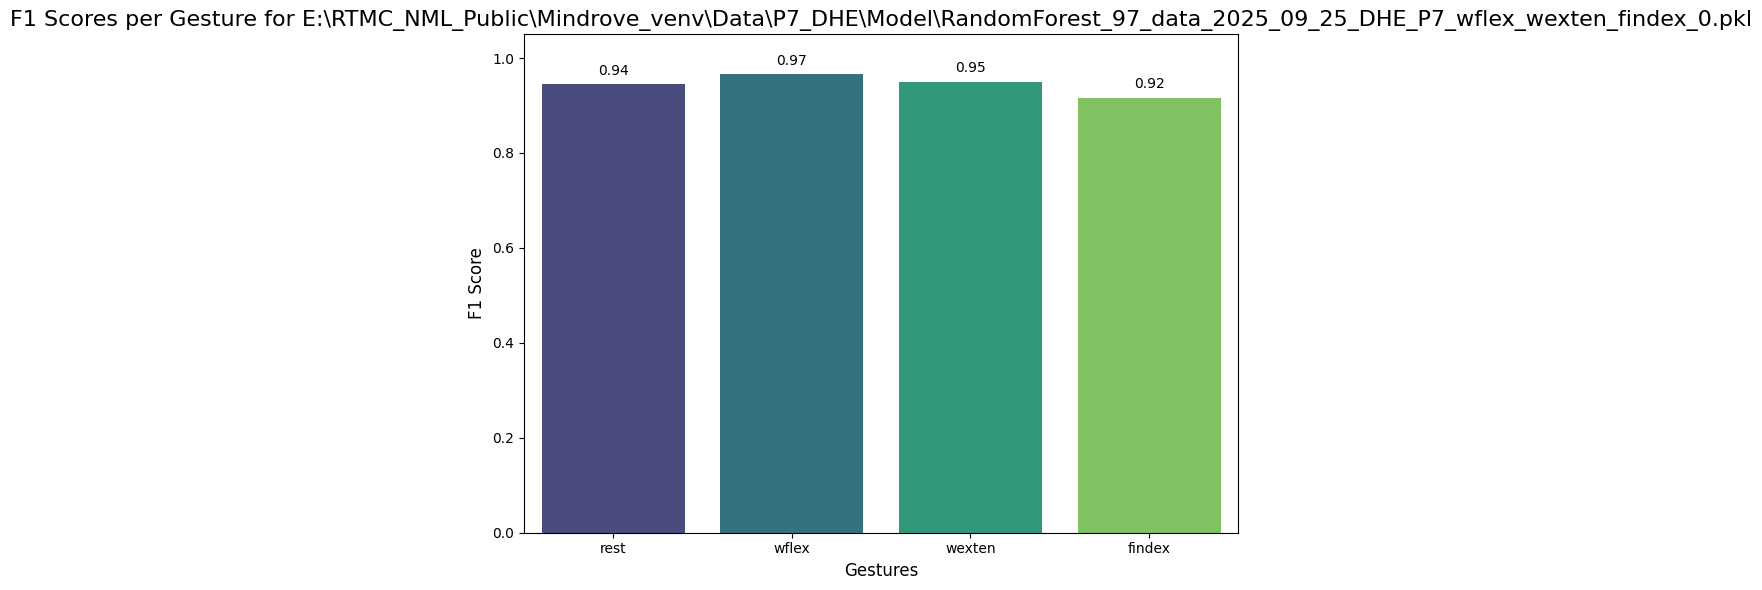

Rest samples statistics:
  Mean amplitude: 7.0354
  Std amplitude: 5.5755
  Threshold: 12.6109

Found 637 windows with pred='rest' and gt!='rest'
Window 176: Mean 4.0267 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 177: Mean 4.1095 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 178: Mean 3.8988 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 179: Mean 4.1600 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 180: Mean 4.1097 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 181: Mean 4.1298 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 182: Mean 4.2225 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 183: Mean 3.9478 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 184: Mean 3.8217 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 185: Mean 3.9153 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 186: Mean 4.2084 <= thresho

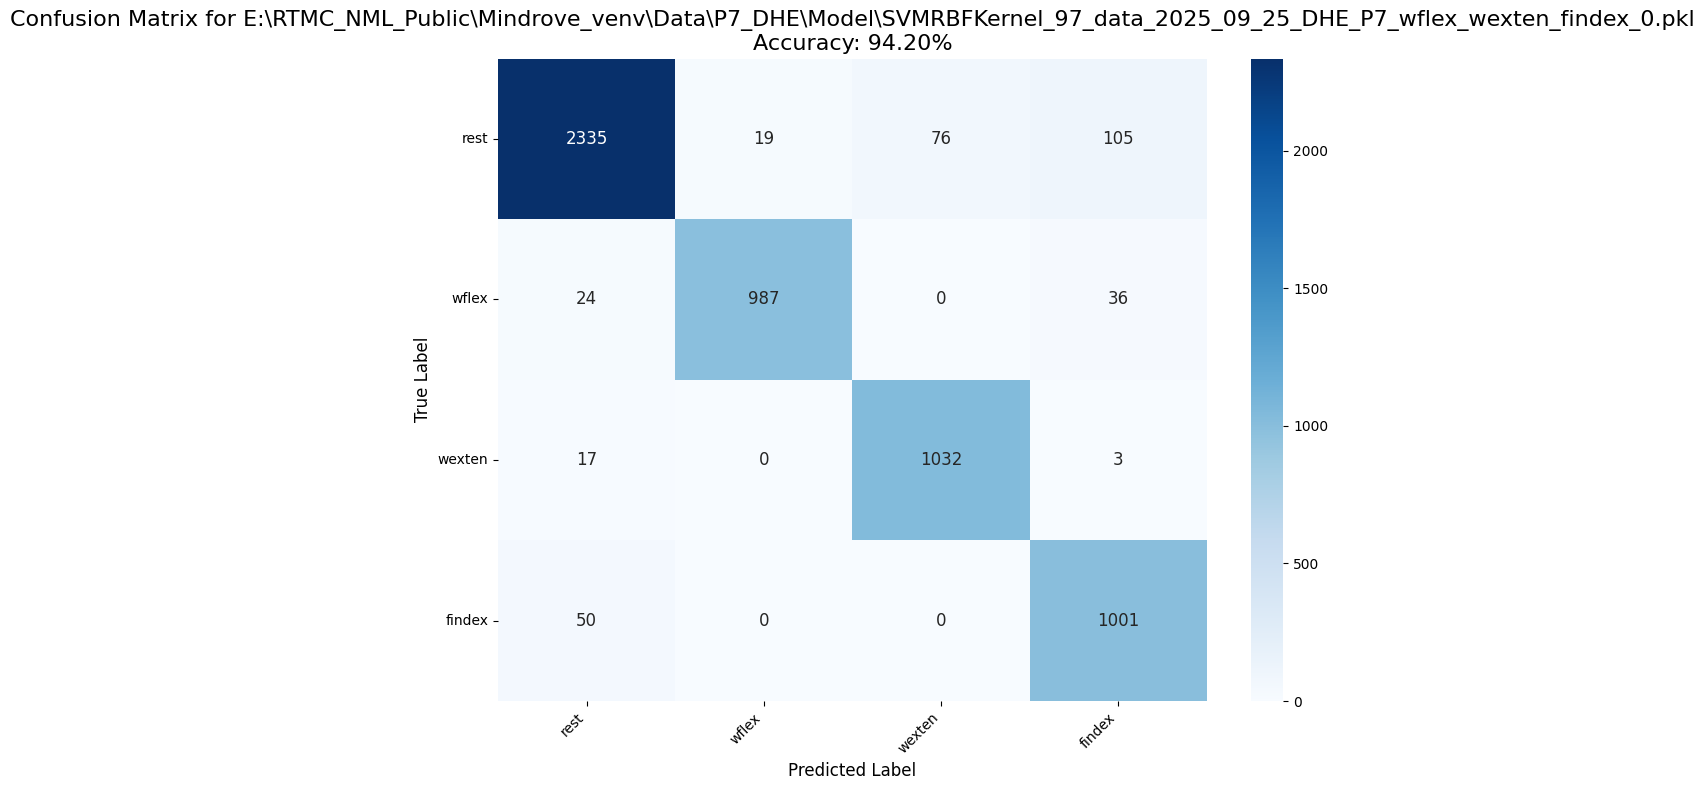

C:\Users\dheem\AppData\Local\Temp\ipykernel_5456\109475387.py:74: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=unique_gestures, y=f1_scores, palette="viridis")


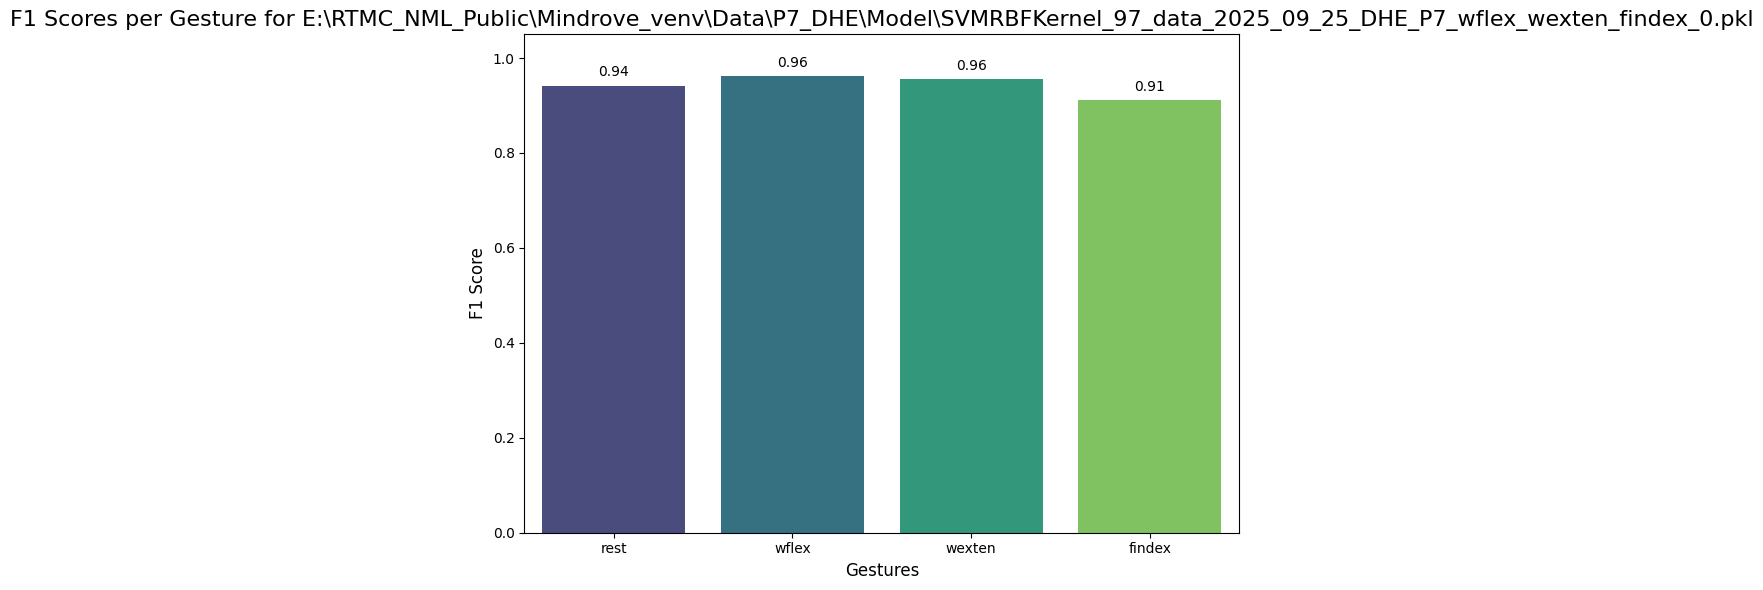

Rest samples statistics:
  Mean amplitude: 7.0354
  Std amplitude: 5.5755
  Threshold: 12.6109

Found 665 windows with pred='rest' and gt!='rest'
Window 176: Mean 4.0267 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 177: Mean 4.1095 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 178: Mean 3.8988 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 179: Mean 4.1600 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 180: Mean 4.1097 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 181: Mean 4.1298 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 182: Mean 4.2225 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 183: Mean 3.9478 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 184: Mean 3.8217 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 185: Mean 3.9153 <= threshold 12.6109, adjusting GT from 'wflex' to 'rest'
Window 186: Mean 4.2084 <= thresho

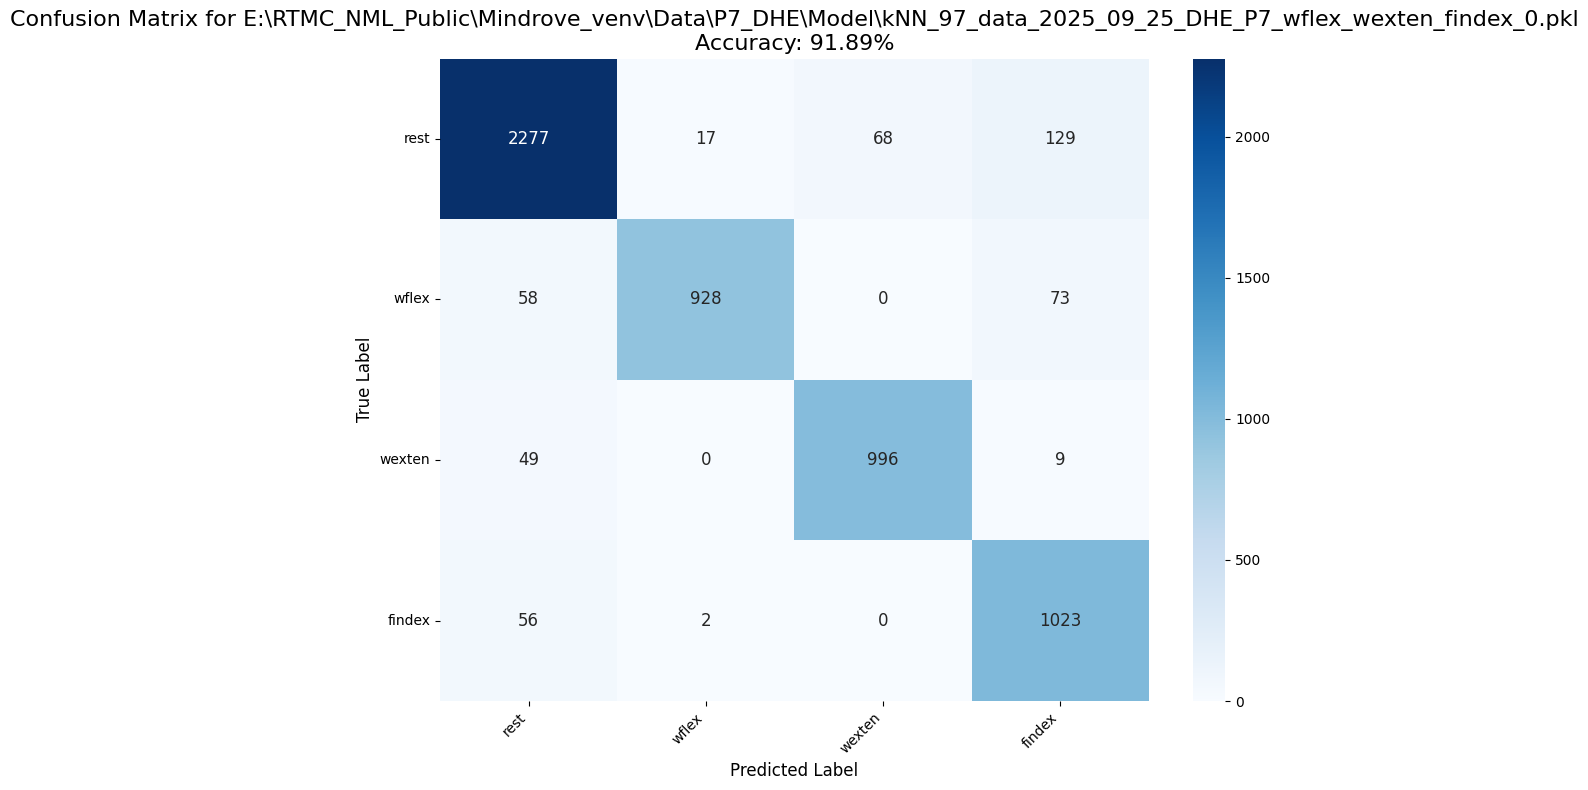

C:\Users\dheem\AppData\Local\Temp\ipykernel_5456\109475387.py:74: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=unique_gestures, y=f1_scores, palette="viridis")


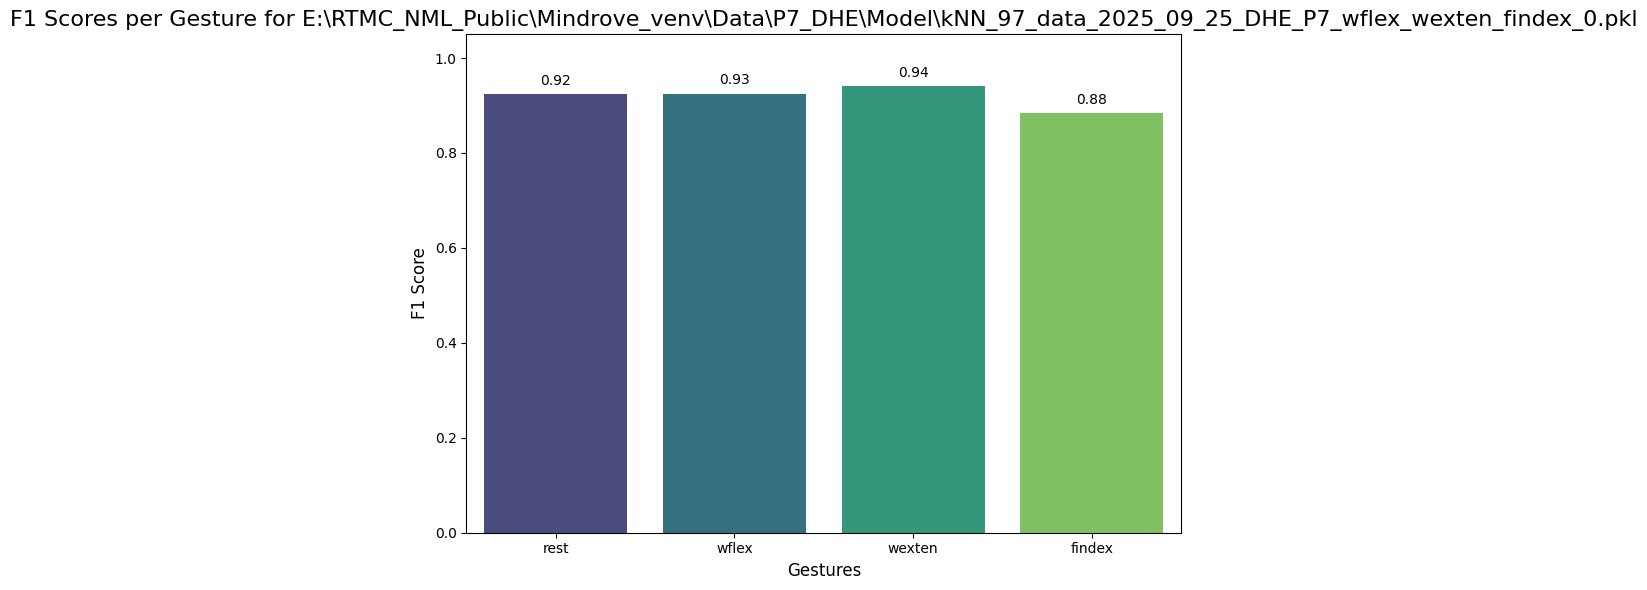

In [ ]:
# Define your model paths
model_paths = [
    "E:\RTMC_NML_Public\Mindrove_venv\Data\P7_DHE\Model\LDA_92_data_2025_09_25_DHE_P7_wflex_wexten_findex_0.pkl",
"E:\RTMC_NML_Public\Mindrove_venv\Data\P7_DHE\Model\MLP_98_data_2025_09_25_DHE_P7_wflex_wexten_findex_0.pkl",
"E:\RTMC_NML_Public\Mindrove_venv\Data\P7_DHE\Model\RandomForest_97_data_2025_09_25_DHE_P7_wflex_wexten_findex_0.pkl",
"E:\RTMC_NML_Public\Mindrove_venv\Data\P7_DHE\Model\SVMRBFKernel_97_data_2025_09_25_DHE_P7_wflex_wexten_findex_0.pkl",
"E:\RTMC_NML_Public\Mindrove_venv\Data\P7_DHE\Model\kNN_97_data_2025_09_25_DHE_P7_wflex_wexten_findex_0.pkl"]

# # Define gesture labels
# unique_gestures = ['rest', 'wflex', 'wexten', 'findex']

# for ml_model_path in model_paths:
#     # Run sliding window with adjustment for each model
#     pred, gt_label = sliding_window_RT_1_4_all_with_adjustment(
#         full_window_df, ml_model_path, full_window_df['Gesture'],
#         window_size=200, stride=200
#     )

#     # Calculate accuracy
#     accuracy = accuracy_score(gt_label, pred)

#     # Confusion matrix
#     cm = confusion_matrix(gt_label, pred, labels=unique_gestures)

#     # Plot confusion matrix
#     plt.figure(figsize=(10, 8))
#     sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
#                 xticklabels=unique_gestures, yticklabels=unique_gestures,
#                 annot_kws={"size": 12})
#     plt.title(f'Confusion Matrix for {ml_model_path}\nAccuracy: {accuracy:.2%}', fontsize=16)
#     plt.ylabel('True Label', fontsize=12)
#     plt.xlabel('Predicted Label', fontsize=12)
#     plt.xticks(rotation=45, ha="right")
#     plt.yticks(rotation=0)
#     plt.tight_layout()
#     plt.show()

from sklearn.metrics import f1_score

# Define gesture labels
unique_gestures = ['rest', 'wflex', 'wexten', 'findex']

for ml_model_path in model_paths:
    # Run sliding window with adjustment for each model
    pred, gt_label = sliding_window_RT_1_4_all_with_adjustment(
        full_window_df, ml_model_path, full_window_df['Gesture'],
        window_size=200, stride=200
    )

    # Calculate accuracy
    accuracy = accuracy_score(gt_label, pred)

    # Confusion matrix
    cm = confusion_matrix(gt_label, pred, labels=unique_gestures)

    # --- Plot Confusion Matrix ---
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=unique_gestures, yticklabels=unique_gestures,
                annot_kws={"size": 12})
    plt.title(f'Confusion Matrix for {ml_model_path}\nAccuracy: {accuracy:.2%}', fontsize=16)
    plt.ylabel('True Label', fontsize=12)
    plt.xlabel('Predicted Label', fontsize=12)
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    # --- F1 Scores ---
    f1_scores = f1_score(gt_label, pred, labels=unique_gestures, average=None)

    # Bar plot of F1 scores
    plt.figure(figsize=(8, 6))
    sns.barplot(x=unique_gestures, y=f1_scores, palette="viridis")
    plt.ylim(0, 1.05)
    plt.title(f'F1 Scores per Gesture for {ml_model_path}', fontsize=16)
    plt.ylabel("F1 Score", fontsize=12)
    plt.xlabel("Gestures", fontsize=12)
    for i, score in enumerate(f1_scores):
        plt.text(i, score + 0.02, f"{score:.2f}", ha="center", fontsize=10)
    plt.tight_layout()
    plt.show()


REAL-TIME PLOTTING ACCURACY

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score
import seaborn as sns
from pathlib import Path
import glob
from collections import defaultdict

In [ ]:
def max_labels(labels):
    """Find the most frequent label in a window"""
    unique, counts = np.unique(labels, return_counts=True)
    return unique[np.argmax(counts)]

def sliding_window_RT(df, labels, ground_truth, window_size=200, stride=200, num_channels=8):
    """Apply sliding window to EMG data and extract labels"""
    signal = df.iloc[:, :num_channels].to_numpy()
    labels = labels.to_numpy()
    ground_truth = ground_truth.to_numpy()
    pred, gt = [], []

    for i in range(0, len(signal) - window_size + 1, stride):
        win = signal[i:i+window_size]
        label = max_labels(labels[i:i+window_size])
        g_label = max_labels(ground_truth[i:i+window_size])
        gt.append(g_label)
        pred.append(label)

    return np.array(pred), np.array(gt)

def process_single_file(file_path, window_size=200, stride=200, num_channels=8,
                       gesture_col='Gesture', label_col='Label',
                       unique_gestures=['rest', 'wflex', 'wexten', 'findex']):
    """Process a single EMG data file and return metrics"""
    try:
        # Load data
        df = pd.read_csv(file_path)

        # Fill NaN values with 'rest'
        df[gesture_col] = df[gesture_col].fillna('rest')
        df[label_col] = df[label_col].fillna('rest')

        # Apply sliding window
        pred, gt_label = sliding_window_RT(df, df[label_col], df[gesture_col],
                                          window_size, stride, num_channels)

        # Calculate metrics
        accuracy = accuracy_score(gt_label, pred)
        precision = precision_score(gt_label, pred, labels=unique_gestures, average='weighted', zero_division=0)
        recall = recall_score(gt_label, pred, labels=unique_gestures, average='weighted', zero_division=0)
        f1 = f1_score(gt_label, pred, labels=unique_gestures, average='weighted', zero_division=0)

        # Calculate per-class metrics
        precision_per_class = precision_score(gt_label, pred, labels=unique_gestures, average=None, zero_division=0)
        recall_per_class = recall_score(gt_label, pred, labels=unique_gestures, average=None, zero_division=0)
        f1_per_class = f1_score(gt_label, pred, labels=unique_gestures, average=None, zero_division=0)

        # Confusion matrix
        cm = confusion_matrix(gt_label, pred, labels=unique_gestures)

        results = {
            'file_name': Path(file_path).stem,
            'accuracy': accuracy,
            'precision': precision,
            'recall': recall,
            'f1_score': f1,
            'confusion_matrix': cm,
            'predictions': pred,
            'ground_truth': gt_label,
            'precision_per_class': dict(zip(unique_gestures, precision_per_class)),
            'recall_per_class': dict(zip(unique_gestures, recall_per_class)),
            'f1_per_class': dict(zip(unique_gestures, f1_per_class))
        }

        return results

    except Exception as e:
        print(f"Error processing {file_path}: {str(e)}")
        return None

def plot_confusion_matrix(cm, unique_gestures, file_name, accuracy, figsize=(8, 6)):
    """Plot confusion matrix for a single file"""
    plt.figure(figsize=figsize)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=unique_gestures, yticklabels=unique_gestures,
                annot_kws={"size": 12})
    plt.title(f'Confusion Matrix - {file_name}\n(Accuracy: {accuracy:.2%})', fontsize=14)
    plt.ylabel('True Label', fontsize=12)
    plt.xlabel('Predicted Label', fontsize=12)
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

In [ ]:
def plot_model_comparison(results_list):
    """Create comprehensive comparison plots"""

    file_names = [r['file_name'] for r in results_list]
    accuracies = [r['accuracy'] * 100 for r in results_list]
    precisions = [r['precision'] * 100 for r in results_list]
    recalls = [r['recall'] * 100 for r in results_list]
    f1_scores = [r['f1_score'] * 100 for r in results_list]

    # Create subplots
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    fig.suptitle('Model Performance Comparison', fontsize=20, fontweight='bold')

    colors = plt.cm.Set3(np.linspace(0, 1, len(file_names)))

    # Accuracy comparison
    bars1 = axes[0, 0].bar(range(len(file_names)), accuracies, color=colors, alpha=0.8, edgecolor='black')
    axes[0, 0].set_title('Accuracy Comparison', fontsize=14, fontweight='bold')
    axes[0, 0].set_ylabel('Accuracy (%)', fontsize=12)
    axes[0, 0].set_xticks(range(len(file_names)))
    axes[0, 0].set_xticklabels(file_names, rotation=45, ha='right')
    axes[0, 0].grid(True, alpha=0.3)

    for bar, acc in zip(bars1, accuracies):
        axes[0, 0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                       f'{acc:.1f}%', ha='center', va='bottom', fontweight='bold')

    # Precision comparison
    bars2 = axes[0, 1].bar(range(len(file_names)), precisions, color=colors, alpha=0.8, edgecolor='black')
    axes[0, 1].set_title('Precision Comparison', fontsize=14, fontweight='bold')
    axes[0, 1].set_ylabel('Precision (%)', fontsize=12)
    axes[0, 1].set_xticks(range(len(file_names)))
    axes[0, 1].set_xticklabels(file_names, rotation=45, ha='right')
    axes[0, 1].grid(True, alpha=0.3)

    for bar, prec in zip(bars2, precisions):
        axes[0, 1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                       f'{prec:.1f}%', ha='center', va='bottom', fontweight='bold')

    # Recall comparison
    bars3 = axes[1, 0].bar(range(len(file_names)), recalls, color=colors, alpha=0.8, edgecolor='black')
    axes[1, 0].set_title('Recall Comparison', fontsize=14, fontweight='bold')
    axes[1, 0].set_ylabel('Recall (%)', fontsize=12)
    axes[1, 0].set_xticks(range(len(file_names)))
    axes[1, 0].set_xticklabels(file_names, rotation=45, ha='right')
    axes[1, 0].grid(True, alpha=0.3)

    for bar, rec in zip(bars3, recalls):
        axes[1, 0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                       f'{rec:.1f}%', ha='center', va='bottom', fontweight='bold')

    # F1-Score comparison
    bars4 = axes[1, 1].bar(range(len(file_names)), f1_scores, color=colors, alpha=0.8, edgecolor='black')
    axes[1, 1].set_title('F1-Score Comparison', fontsize=14, fontweight='bold')
    axes[1, 1].set_ylabel('F1-Score (%)', fontsize=12)
    axes[1, 1].set_xticks(range(len(file_names)))
    axes[1, 1].set_xticklabels(file_names, rotation=45, ha='right')
    axes[1, 1].grid(True, alpha=0.3)

    for bar, f1 in zip(bars4, f1_scores):
        axes[1, 1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                       f'{f1:.1f}%', ha='center', va='bottom', fontweight='bold')

    plt.tight_layout()

    plt.show()



In [ ]:
def plot_grouped_metrics(results_list):
    """Create grouped bar plot for all metrics"""
    if not results_list:
        print("No results to plot")
        return

    file_names = [r['file_name'] for r in results_list]
    metrics = {
        'Accuracy': [r['accuracy'] * 100 for r in results_list],
        'Precision': [r['precision'] * 100 for r in results_list],
        'Recall': [r['recall'] * 100 for r in results_list],
        'F1-Score': [r['f1_score'] * 100 for r in results_list]
    }

    x = np.arange(len(file_names))
    width = 0.2
    multiplier = 0

    fig, ax = plt.subplots(figsize=(14, 8))

    colors = ['red', 'blue','pink', 'yellow']

    for i, (metric, values) in enumerate(metrics.items()):
        offset = width * multiplier
        bars = ax.bar(x + offset, values, width, label=metric, color=colors[i], alpha=0.8, edgecolor='black')

        # Add value labels on bars
        for bar, value in zip(bars, values):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                   f'{value:.1f}%', ha='center', va='bottom', fontweight='bold', fontsize=9)

        multiplier += 1

    ax.set_xlabel('Models', fontweight='bold', fontsize=12)
    ax.set_ylabel('Performance (%)', fontweight='bold', fontsize=12)
    ax.set_title('Model Performance Comparison - All Metrics', fontweight='bold', fontsize=16)
    ax.set_xticks(x + width * 1.5)
    ax.set_xticklabels(file_names, rotation=45, ha='right')
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
    ax.grid(True, alpha=0.3)
    ax.set_ylim(0, max(max(values) for values in metrics.values()) + 10)

    plt.tight_layout()
    plt.show()

In [ ]:
def compare_emg_models(file_paths, window_size=200, stride=200, num_channels=8,
                      gesture_col='Gesture', label_col='Label',
                      unique_gestures=['rest', 'wflex', 'wexten', 'findex'],
                      output_dir=None):
    """ Main function to compare multiple EMG model files """

    if isinstance(file_paths, str):
        if '*' in file_paths:
            file_paths = glob.glob(file_paths)
        else:
            file_paths = glob.glob(f"{file_paths}/*.csv")

    results_list = []
    for file_path in file_paths:
        print(f"Processing: {Path(file_path).name}")
        result = process_single_file(file_path, window_size, stride, num_channels,
                                   gesture_col, label_col, unique_gestures)
        if result:
            results_list.append(result)


    for result in results_list:
        plot_confusion_matrix(result['confusion_matrix'], unique_gestures,
                            result['file_name'], result['accuracy'])

    # Create comparison plots
    plot_model_comparison(results_list)
    plot_grouped_metrics(results_list)

    summary_stats = {
        'num_models': len(results_list),
        'avg_accuracy': np.mean([r['accuracy'] for r in results_list]),
        'std_accuracy': np.std([r['accuracy'] for r in results_list]),
        'best_model': max(results_list, key=lambda x: x['accuracy'])['file_name'],
        'worst_model': min(results_list, key=lambda x: x['accuracy'])['file_name'],
        'best_accuracy': max([r['accuracy'] for r in results_list]),
        'worst_accuracy': min([r['accuracy'] for r in results_list])
    }



    return {
        'results_list': results_list,
        'summary_stats': summary_stats
    }

Processing: data_2025_09_23_DEV_P3_MLP_Full_Window_0.csv
Error processing E:\RTMC_NML_Public\Mindrove_venv\Data\P3_DEV\Online\data_2025_09_23_DEV_P3_MLP_Full_Window_0.csv: 'Gesture'
Processing: data_2025_09_23_DEV_P3_MLP_Full_Window_0_full_window_log.csv


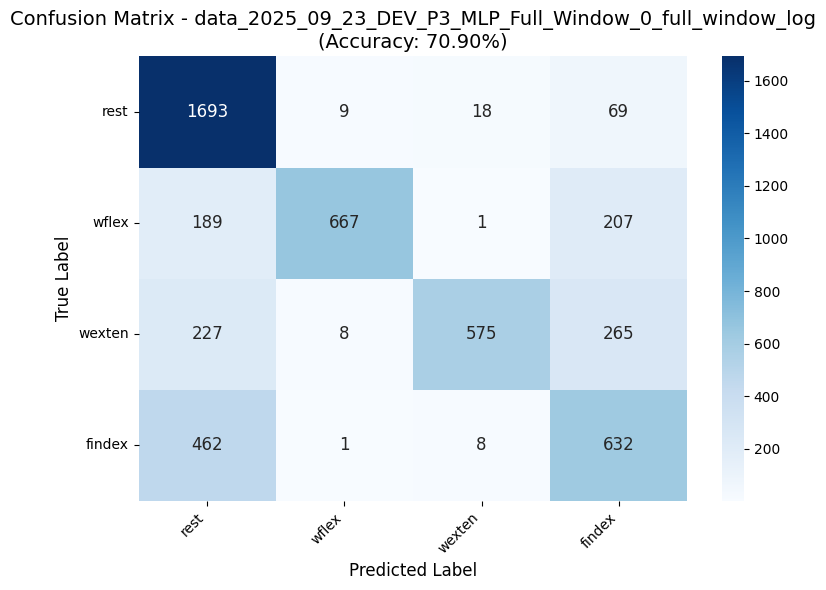

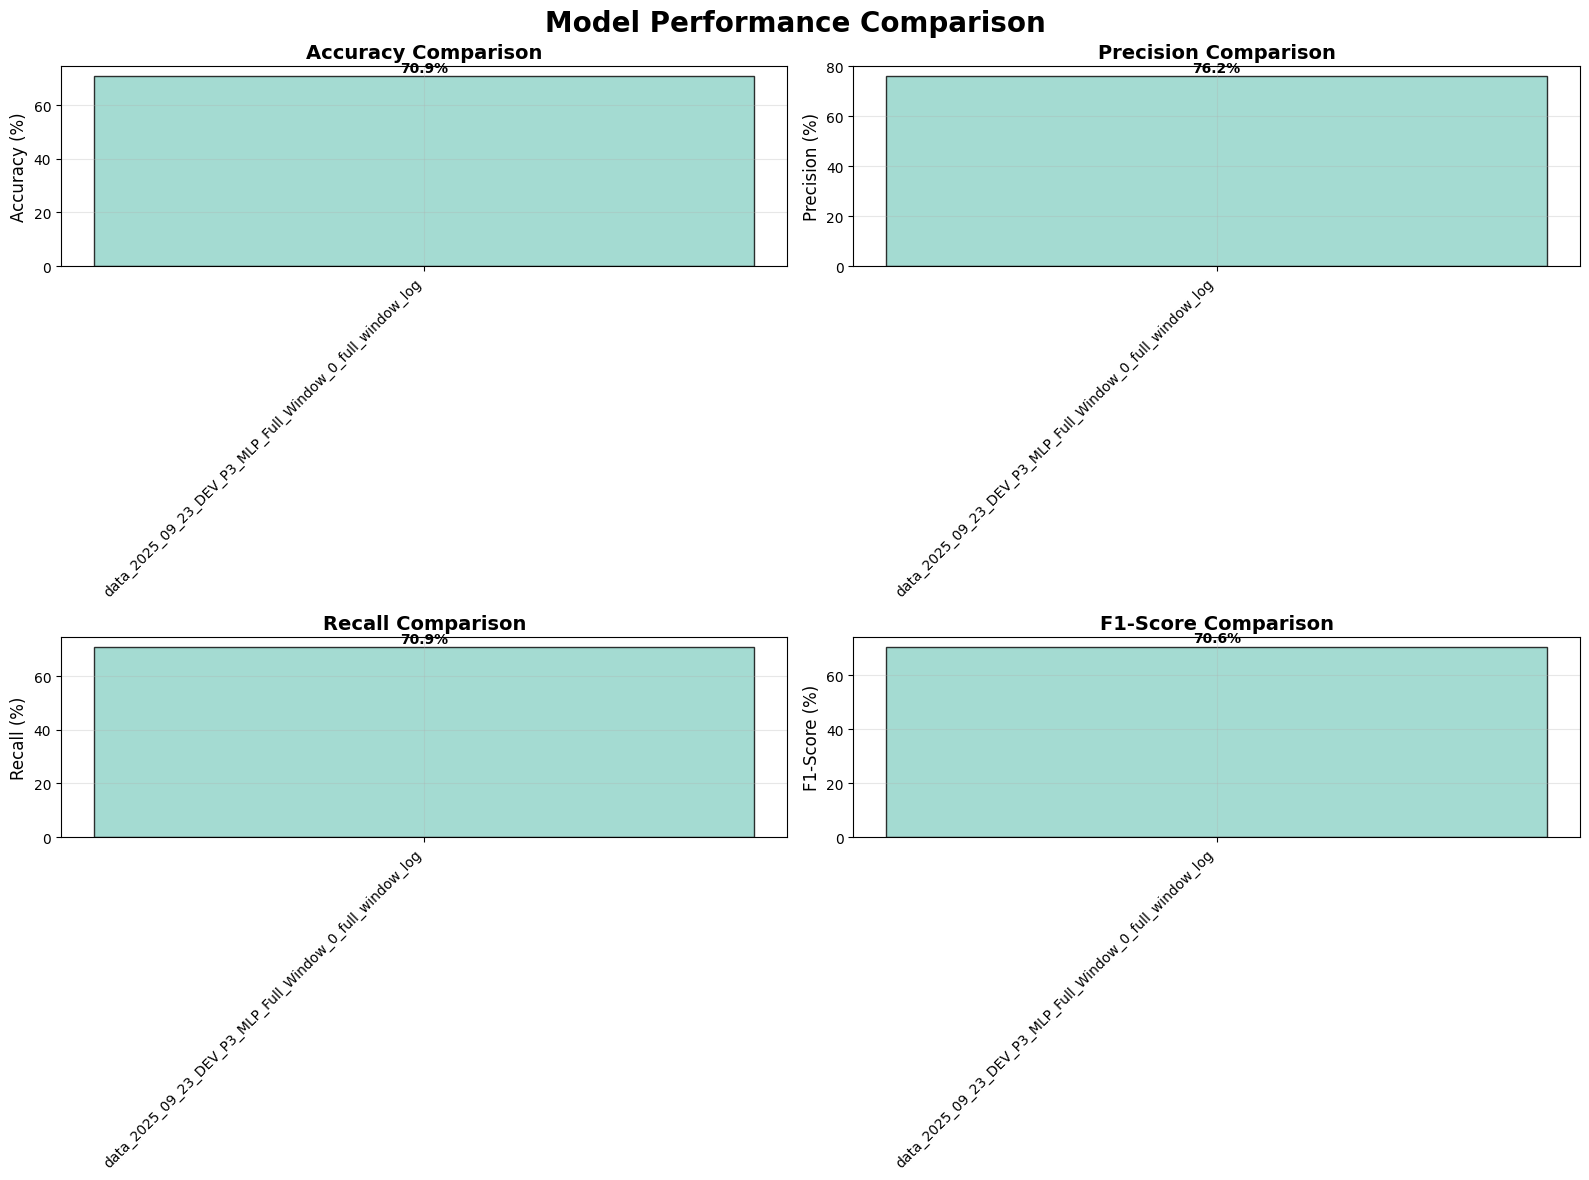

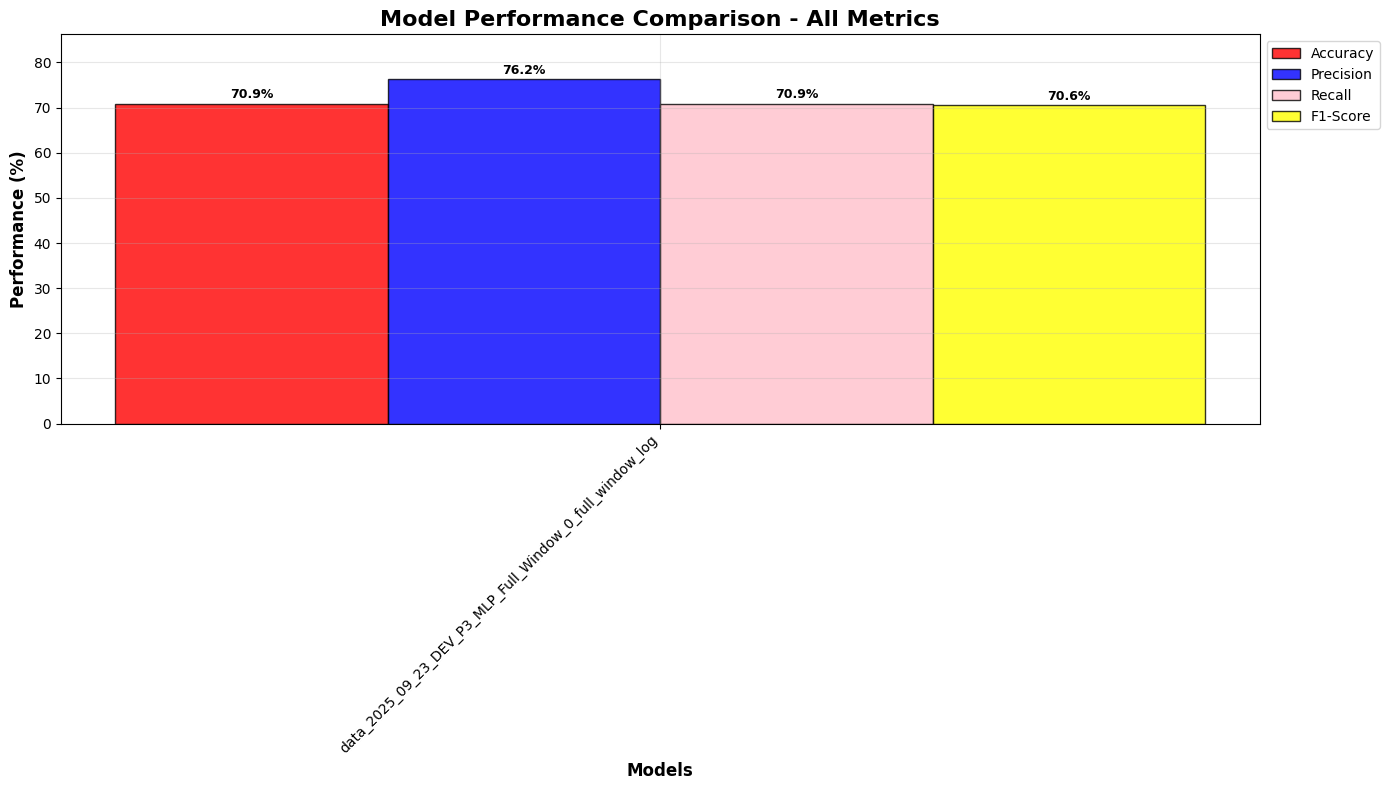

In [ ]:
results = compare_emg_models("E:\RTMC_NML_Public\Mindrove_venv\Data\P3_DEV\Online\*full_window*.csv")

In [ ]:
data = pd.read_csv("E:/RTMC_NML_Public/data_2025_09_24_DEF_P6_Full_Window_0.csv")

In [ ]:
data.shape

(170734, 8)

In [ ]:
(1130200, 11)